  <span style="font-size: 25pt; font-weight: bold; color: #009dcd;">**ANÁLISIS DE VARIACIÓN DE PRECIOS DE LOS MODELOS DE BMW EN 2026 POR PAÍSES**</span>

 
<span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**1. LIBRERÍA PANDAS: CARGAR ARCHIVOS EN FORMATO .csv**</span>

In [1]:
import pandas as pd
import numpy as np
import io
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from pathlib import Path
import re 

In [2]:
#Archivos que se van a utilizar de aquí en adelante: 
fichero_bmw = 'bmw_prices_2026.csv'
fichero_suiza = 'precios_suiza.csv'

path_bmw = Path(fichero_bmw)

#Si el archivo no está en ese lugar, se busca automáticamente en directorio 
if not path_bmw.exists():
    candidates = [
        Path.cwd() / path_bmw.name, 
        Path.cwd().parent / path_bmw.name
    ]
    path_bmw = next((p for p in candidates if p.exists()), path_bmw)
    
#Cargar el df principal de forma definitiva: 
try:
    df = pd.read_csv(path_bmw, sep=';')
    print("¡Archivo principal de precios cargado con éxito en la variable 'df'!")
except FileNotFoundError:
    print(f"❌ Error: No se encontró el archivo '{fichero_bmw}'. Asegúrate de subirlo a la carpeta de este notebook.")

¡Archivo principal de precios cargado con éxito en la variable 'df'!



<span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**2. CARGA DE ARCHIVOS - LOCAL**</span>

In [3]:
r = 'bmw_prices_2026.csv'
candidates = [
    Path(r),
    Path(r).expanduser(),
    Path.cwd() / Path(r).name,
    Path.cwd().parent / Path(r).name,
]

csv_path = next((p for p in candidates if p.exists()), None)

if csv_path is None:
    raise FileNotFoundError(
        f"No se encontró el archivo CSV en ninguna de estas rutas:\n"
        f"{[str(p) for p in candidates]}\n"
        f"Revisa la variable 'r' o sube el archivo a la carpeta del notebook."
    )

df = pd.read_csv(csv_path, sep=';')
df.head()

,Modelo,España,Alemania,Francia,Portugal,Italia
0,Serie 1 116i,35150,34250,36200,35200,35500
1,Serie 1 118d,40250,39350,38900,41650,40210
2,Serie 2 Coupe 218i,50300,46300,60925,50450,46200
3,Serie 2 coupe 220d,56500,53400,61540,59450,54200
4,Serie 2 Gran Coupe 218i,38650,37750,50250,38700,39000



<span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**3. MOSTRAR PRIMERAS CINCO FILAS DEL DF**</span>

In [4]:
import pandas as pd
import io

# Usa la ruta válida que ya se encontró antes en este notebook
df = pd.read_csv(csv_path, sep=';')

# Display the first 5 rows of the DataFrame
display(df.head(5))

,Modelo,España,Alemania,Francia,Portugal,Italia
0,Serie 1 116i,35150,34250,36200,35200,35500
1,Serie 1 118d,40250,39350,38900,41650,40210
2,Serie 2 Coupe 218i,50300,46300,60925,50450,46200
3,Serie 2 coupe 220d,56500,53400,61540,59450,54200
4,Serie 2 Gran Coupe 218i,38650,37750,50250,38700,39000



<span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**4. MOSTRAR ÚLTIMAS DIEZ FILAS DEL DF**</span>

**4.1. Mostrar las diez últimas filas del df**

In [5]:
#Display last ten rows

r = '/Users/adriana/Desktop/ANALISIS CODIGO /Análisis precios BMW/bmw_prices_2026.csv'
df = pd.read_csv(r, sep=';')
display(df.tail(10))

,Modelo,España,Alemania,Francia,Portugal,Italia
68,Serie 4 Cabrio M440d xDrive,94500,86200,86500,101850,92400
69,X1 M35i xDrive,73750,65600,67650,68150,63700
70,X2 M35i xDrive,75250,67100,69900,70400,65300
71,X3 M50i xDrive,91700,85200,88200,99450,92300
72,X5 M,183450,168500,172350,232050,160000
73,X5 M60i xDrive,128850,120000,122000,154650,119300
74,X6 M,187050,171900,175000,235000,167000
75,X6 M60i xDrive,134450,123500,123000,157550,123100
76,X7 M60i xDrive,155400,138000,140000,182550,142500
77,XM,190900,135500,149850,155550,137500


<span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**5. MOSTRAR FILAS INTERMEDIAS: Con df.iloc()**</span>


In [6]:
# Display rows from index 14 to 24 (inclusive)
display(df.iloc[14:25])

,Modelo,España,Alemania,Francia,Portugal,Italia
14,Serie 7 730i,125000,124000,128000,115000,127000
15,Serie 7 740d,124200,119900,120000,142450,129850
16,Serie 2 Active Tourer 218i,42550,38750,45000,37800,37720
17,Serie 2 active Tourer 218d,44850,42450,48300,47400,41920
18,Serie 3 Touring 320i,53150,48300,49600,51850,50960
19,Serie 3 Touring 318d,52200,52800,54650,59250,55660
20,Serie 5 Touring 520i,66150,62000,64000,67200,70700
21,Serie 5 Touring 520d,66050,64300,65800,70450,71800
22,X1 sDrive 20i,48300,45100,46400,58100,44400
23,X1 sDrive 20d,46850,47700,48700,54150,47100



<span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**6. ANÁLISIS PRELIMINAR**</span>

**6.1.Head:**


In [7]:
# Display head of DataFrame
df.head(2)

,Modelo,España,Alemania,Francia,Portugal,Italia
0,Serie 1 116i,35150,34250,36200,35200,35500
1,Serie 1 118d,40250,39350,38900,41650,40210


**6.2. Datos estadísticos básicos: df.describe()**




In [8]:
df.describe()

,España,Alemania,Francia,Portugal,Italia
count,78.000000,78.000000,78.000000,78.000000,78.000000
mean,82962.564103,76326.282051,79886.217949,87437.820513,77999.743590
std,36218.540866,30214.782789,30465.299999,41553.105738,30556.570275
min,35150.000000,34250.000000,36200.000000,35200.000000,35500.000000
25%,56837.500000,53525.000000,60412.500000,57987.500000,55540.000000
50%,69040.000000,67000.000000,69100.000000,72325.000000,70300.000000
75%,100087.500000,94025.000000,99225.000000,108437.500000,93975.000000
max,190900.000000,171900.000000,175000.000000,235000.000000,167000.000000


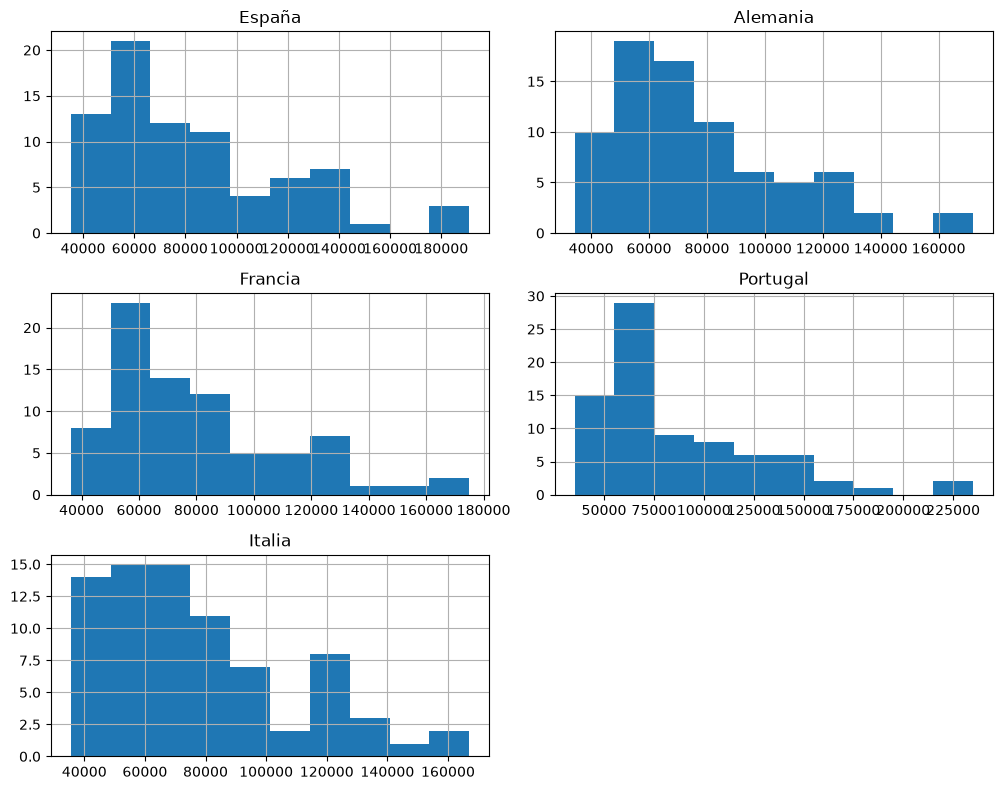

In [9]:
#Crear histograma
df.hist(figsize=(10, 8))
plt.tight_layout()
plt.show()

**6.3. Cuántas filas y columnas tenemos: Shape df.shape()**

In [10]:
# Shape shown as a tuple
display(df.shape)

(78, 6)

**6.4. Tipo de datos:  df.type()**

In [11]:
import pandas as pd
# Data type from bmw_prices_2026 DataFrame
df.dtypes

Modelo        str
España      int64
Alemania    int64
Francia     int64
Portugal    int64
Italia      int64
dtype: object

<span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**7. OTROS DATOS DE INTERÉS**</span>


**7.1. Modelo más caro en la columna 'Alemania'**

In [12]:
#Most expensive model from the column 'Alemania'

#Encontrar el precio más alto en la columna del país "Alemania"
idx_max_alemania = df['Alemania'].idxmax()
modelo_caro_alemania = df.loc[idx_max_alemania, 'Modelo']
precio_caro_alemania = df.loc[idx_max_alemania,'Alemania']
print(f"El modelo más caro en Alemania es: {modelo_caro_alemania}({precio_caro_alemania:,.2f}€)")

El modelo más caro en Alemania es: X6 M(171,900.00€)


**7.2. Modelo más asequible de la columna 'Francia'**

In [13]:
#Encontrar el precio más bajo en la columna del país "Francia"

idx_min_francia= df['Francia'].idxmin()
modelo_barato_francia = df.loc[idx_min_francia,'Modelo']
precio_barato_francia = df.loc[idx_min_francia, 'Francia']
print(f"El modelo más asequible en Francia es: {modelo_barato_francia} ({precio_barato_francia:,.2f}€)")

El modelo más asequible en Francia es: Serie 1  116i (36,200.00€)


**7.3. Modelo más caro de la columna 'Portugal'**

In [14]:
# Normalizar los encabezados para eliminar espacios al inicio o al final
df.columns = df.columns.astype(str).str.strip()

idx_max_portugal = df["Portugal"].idxmax()
modelo_caro_portugal = df.loc[idx_max_portugal, "Modelo"]
precio_caro_portugal = df.loc[idx_max_portugal, "Portugal"]

print(f"El modelo más caro en Portugal es: {modelo_caro_portugal} ({precio_caro_portugal:,.2f}€)")

El modelo más caro en Portugal es: X6 M (235,000.00€)


**7.4. Diferencia de precios (%) de un mismo modelo (M4 Coupe) comparando las columnas 'España' y 'Alemania'**

In [15]:
#Diferencia de precio en modelo 'M4 Coupe' en porcentaje, entre los países 'España' y 'Alemania'

# Filtrar modelo "M4 Coupe" usando la columna 'Modelo'
m4_coupe_data = df[df['Modelo'].str.contains('M4 Coupe', na=False)]

#Porcentaje de diferencia entre el precio del M4 en España y Alemania
precio_m4_coupe_españa = m4_coupe_data['España'].values[0]
precio_m4_coupe_alemania = m4_coupe_data['Alemania'].values[0]
diferencia_precio_españa_alemania = (precio_m4_coupe_españa - precio_m4_coupe_alemania) / precio_m4_coupe_españa *100
print(f"La diferencia de precio del M4 Coupe entre España y Alemaia es de {diferencia_precio_españa_alemania:,.2f})%")


La diferencia de precio del M4 Coupe entre España y Alemaia es de 24.46)%


**Represetación gráfica de la diferencia de precios del M4 Coupe entre España y Alemania**

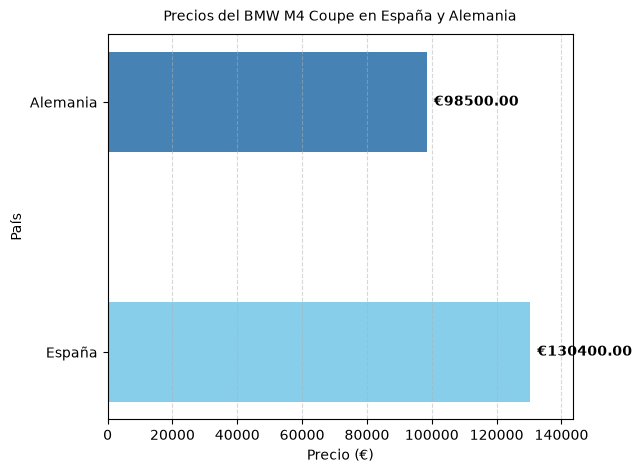

In [16]:
import matplotlib.pyplot as plt
import numpy as np

#1. Configuración del gráfico de barras
plt.figure(figsize=(6,5))

# Extract prices for M4 Coupe in Spain and Germany
precio_m4_coupe_españa = m4_coupe_data['España'].values[0]
precio_m4_coupe_alemania = m4_coupe_data['Alemania'].values[0]

countries = ['España', 'Alemania']
prices = [precio_m4_coupe_españa, precio_m4_coupe_alemania]

barra = plt.barh(countries, prices, color=['skyblue', 'steelblue'], height=0.4)

#2. Añadir valor numérico de cada barra
plt.bar_label(barra, fmt='€%.2f', padding=5, fontsize=10, color='black', weight='bold')

#3.Títulos y etiquetas
plt.title('Precios del BMW M4 Coupe en España y Alemania', fontsize=10, pad=10)
plt.xlabel('Precio (€)', fontsize=10)
plt.ylabel('País', fontsize=10)

# Extra: "lim" para ajustar el límite superior de manera que haya espacio para el texto
plt.xlim(0, max(prices) * 1.1) # Adjust x-limit to accommodate labels
plt.grid(axis='x', linestyle='--', alpha=0.5)


#4. Mostrar gráfico
plt.show()

<span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**8. CHECK DE NULOS**</span>


In [17]:
# Comprobar nulos en dataframe
df.isnull().sum()

Modelo      0
España      0
Alemania    0
Francia     0
Portugal    0
Italia      0
dtype: int64


<span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**9. PRECIOS SUPERIORES / INFERIORES**</span>

**9.1. Modelos con un precio INFERIOR a 70.000€ de la columna 'Portugal'**

In [18]:
#Filtrar modelos con un precio INFERIOR A €70000.0  (columna 'Portugal')

datos= {'Modelo':['Serie_1_116_i', 'Serie_4_coupe_420_d', 'Serie_3_Touring_330_e','Z_4_sDrive','XM', 'Serie_2_Coupe_220d'],'Precio':[35200.0, 61050.0, 58500.0, 71200.0, 155550.0, 59450]}
example_df= pd.DataFrame(datos)
filtrar_df= example_df[example_df['Precio']<70000.0]
print(filtrar_df)

                  Modelo   Precio
0          Serie_1_116_i  35200.0
1    Serie_4_coupe_420_d  61050.0
2  Serie_3_Touring_330_e  58500.0
5     Serie_2_Coupe_220d  59450.0


**9.2. Modelos cuyo precio está comprendido entre 45.000€ y 90.000€ en la columna 'Alemania'**

In [19]:
#Filtrar modelos con un precio COMPRENDIDO ENTRE 45000.0 y 90000.0 (columna 'Alemania')

import pandas as pd
datos= {'Modelo': ['Serie_4_Coupe_420_i','Serie_5_520_d','Serie_3_Touring_320_i','X_6_M','M_3_Touring','Serie_1_118_d'], 'Precio':[53900.0,62300.0,48300.0,171900.0,108900.0,39350.0]}
example_df= pd.DataFrame(datos)
filtrar_df= example_df[example_df['Precio'].between(45000.0, 90000.0)]
print(filtrar_df)

                  Modelo   Precio
0    Serie_4_Coupe_420_i  53900.0
1          Serie_5_520_d  62300.0
2  Serie_3_Touring_320_i  48300.0


**9.3. Modelos con precio inferior a 40.000€ en la columna 'Francia'**

In [20]:
#Filtrar modelos con un precio INFERIOR A 40000.0 (columna 'Francia')

import pandas as pd
datos = {'Modelo': ['Serie_4_Coupe_420_i','Serie_5_520_d','Serie_3_Touring_320_i','X_6_M','M_3_Touring','Serie_1_118_d'],
         'Precio': [53900,62300,48300,171900,108900,39350]}

example_df = pd.DataFrame(datos)
filtrar_df = example_df[example_df['Precio'] < 40000.0]
print(filtrar_df)

          Modelo  Precio
5  Serie_1_118_d   39350



<span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**10. MATRIZ DE CORRELACIÓN**</span>

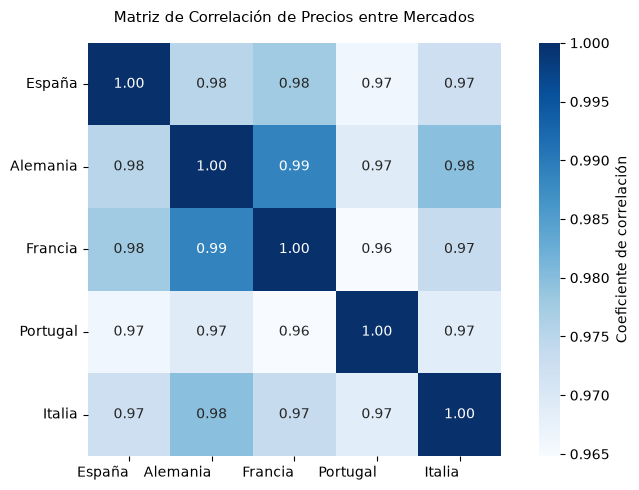

In [21]:
#Matriz de correlación
# Seleccionar solo las columnas numéricas para la correlación
matriz_corr = df.select_dtypes(include=np.number).corr()

#Tamaño de figuras
plt.figure(figsize=(8,5))

#Visualización (seaborn): mapa de calor optimizado
sns.heatmap(matriz_corr,
            annot=True,
            cmap='Blues',
            fmt=".2f",
            square=True,
            cbar_kws={'label': 'Coeficiente de correlación'})

#personalización (para evitar que los nombres se solapen)
plt.title('Matriz de Correlación de Precios entre Mercados', fontsize=11, pad=15)
plt.xticks(rotation=0, ha='right')
plt.yticks(rotation=0)
plt.tight_layout() #Para reajustar el margen 

plt.show()

Breve análisis del heatmap o mapa de calor:
En el caso de esta matriz, todos los datos muestran una correlacion muy alta, y puede llevar a deducir que influyen factores externos tales como:

*   inflación,
*   o costes asociados a la fabricación, como el de la energía.

También hay que tener aquí en cuenta aquellos modelos cuyo precio es elevado por sistema, independientemente de que modelos inferiores varíen su precio en mayor o menor medida.


<span style="font-size: 15pt; font-weight: bold; color: #009dcd;"> **11. SORT_VALUES: Ordenar en sentido ascendente o descendente** </span>

In [22]:
#Ordenar precios en sentido DESCENDENTE con sort_values()
r = 'bmw_prices_2026.csv'
df.sort_values(by='España', ascending=False).head(10)

,Modelo,España,Alemania,Francia,Portugal,Italia
77,XM,190900,135500,149850,155550,137500
74,X6 M,187050,171900,175000,235000,167000
72,X5 M,183450,168500,172350,232050,160000
76,X7 M60i xDrive,155400,138000,140000,182550,142500
66,M4 Cabrio,140000,114100,131250,142700,124000
50,Serie 7 750e,134850,128100,131000,137000,135200
75,X6 M60i xDrive,134450,123500,123000,157550,123100
30,X6 xDrive 40i M Sport,134450,123500,124290,116300,97800
58,M3 Touring,134350,108900,108950,137200,120000
63,M4 Coupe,130400,98500,102650,130850,106000


 <span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**12. ELIMINACIÓN DE COLUMNAS - CREACIÓN DE NUEVO DF**</span>

In [23]:
#Eliminación de columnas (nuevo DF)
#Ejemplo: eliminar columna "Francia"

r = 'bmw_prices_2026.csv'
new_df = df.drop ('Francia', axis=1)
new_df.head()


,Modelo,España,Alemania,Portugal,Italia
0,Serie 1 116i,35150,34250,35200,35500
1,Serie 1 118d,40250,39350,41650,40210
2,Serie 2 Coupe 218i,50300,46300,50450,46200
3,Serie 2 coupe 220d,56500,53400,59450,54200
4,Serie 2 Gran Coupe 218i,38650,37750,38700,39000


**12.1. Definir el tamaño del nuevo df**

In [24]:
#Definir tamaño del nuevo df (new_df)
print(new_df.shape)

(78, 5)


<span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**13. ELIMINACIÓN DE FILAS CON ÍNDICES**</span>

In [25]:
#Eliminar filas: indicando índices
r = 'bmw_prices_2026.csv'
df.iloc[:40]
print(df)

                     Modelo  España  Alemania  Francia  Portugal  Italia
0             Serie 1  116i   35150     34250    36200     35200   35500
1             Serie 1  118d   40250     39350    38900     41650   40210
2       Serie 2 Coupe  218i   50300     46300    60925     50450   46200
3       Serie 2 coupe  220d   56500     53400    61540     59450   54200
4   Serie 2 Gran Coupe 218i   38650     37750    50250     38700   39000
..                      ...     ...       ...      ...       ...     ...
73           X5 M60i xDrive  128850    120000   122000    154650  119300
74                     X6 M  187050    171900   175000    235000  167000
75           X6 M60i xDrive  134450    123500   123000    157550  123100
76           X7 M60i xDrive  155400    138000   140000    182550  142500
77                       XM  190900    135500   149850    155550  137500

[78 rows x 6 columns]


**13.1. Filas NO CONSECUTIVAS: Con objeto de mostrar modelos diferentes sin que se repitan entre ellos**

In [26]:
#Seleccionar filas del df NO CONSECUTIVAS
df.iloc[[1,10,17,25,29,40,42,56,61,72]]


,Modelo,España,Alemania,Francia,Portugal,Italia
1,Serie 1 118d,40250,39350,38900,41650,40210
10,Serie 3 320i,51150,47000,58190,50550,49660
17,Serie 2 active Tourer 218d,44850,42450,48300,47400,41920
25,X2 sDrive 18d,48350,49200,51200,55100,49050
29,X5 xDrive 30d,96150,98100,102700,112300,87000
40,i7 eDrive 50,116000,115900,118900,122000,118000
42,iX2 eDrive 20,51300,51000,55100,51100,45100
56,M2,97500,77500,81550,97900,82140
61,Serie 3 M340d xDrive,84500,77500,80150,93450,77300
72,X5 M,183450,168500,172350,232050,160000


**13.2. Combinación de filas con columnas específicas**

In [27]:
#Combinar filas con columnas específicas
#Aquí tomamos como referencia la columna de precios de Alemania
df.iloc[[1, 14, 25, 31, 49], [0, 2]]

,Modelo,Alemania
1,Serie 1 118d,39350
14,Serie 7 730i,124000
25,X2 sDrive 18d,49200
31,X6 xDrive 30d M Sport,90500
49,Serie 5 Touring 530e,68700


**13.3. Combinación de filas: con objeto de mostrar solamente los modelos híbridos del catálogo**

In [28]:
#Mostrar solo modelos híbridos del catálogo
#Para ello se buscan aquellos modelos cuya numeración vaya seguida de la letra 'e' 
#(De esta forma: si hay cambios en el catálogo, va a buscar sólo aquellos que llevan la 'e')
#Ejemplo: Serie 3 Touring 330e 
df[df['Modelo'].str.contains(r'\b\d{2,3}e\b|xDrive\d{2}e', regex=True, na=False)]

,Modelo,España,Alemania,Francia,Portugal,Italia
45,Serie 2 Active Tourer 225e,51900,49150,52650,47700,46300
46,Serie 3 330e,61250,63300,65800,57200,55500
47,Serie 3 Touring 330e,65750,64600,69300,58500,56500
48,Serie 5 530e,73350,68700,69650,71750,73100
49,Serie 5 Touring 530e,75950,68700,71250,73750,76700
50,Serie 7 750e,134850,128100,131000,137000,135200
51,X1 xDrive 25e,56800,51600,52800,56000,46800
52,X3 xDrive 30e,67300,66900,68900,73900,71500
53,X5 xDrive 50e,104600,97900,101950,106900,95500


**13.4. Representación gráfica de la diferencia de precio por países de un modelo concreto (mostrando las versiones en gasolina y diésel)**

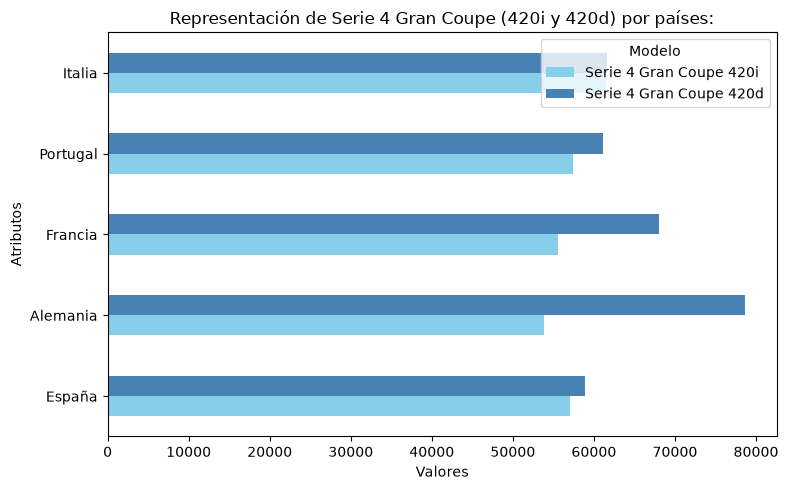

In [29]:
modelos_buscados = ['Serie 4 Gran Coupe 420i', 'Serie 4 Gran Coupe 420d']
fila_coche = df[df['Modelo'].isin(modelos_buscados)]

#Gráfico de barras:
fila_numerica = fila_coche.set_index('Modelo')

# Obtener el nombre del modelo para el título
model_name = fila_coche['Modelo'].iloc[0]

# Use a list of specific colors for each model
colors = ['skyblue', 'steelblue'] 
fila_numerica.T.plot(kind='barh', figsize=(8, 5), legend=True, color=colors)

#Personalización
plt.title(f'Representación de Serie 4 Gran Coupe (420i y 420d) por países:')
plt.xlabel('Valores')
plt.ylabel('Atributos')
plt.tight_layout()
plt.show()

In [30]:
fila_ordenada = fila_coche.sort_values(by='España')
precio_coche_1 = fila_coche['España'].iloc[0]
precio_coche_2 = fila_coche['España'].iloc[1]

coche_barato = fila_ordenada['Modelo'].iloc[0]
precio_minimo = fila_ordenada['España'].iloc[0]
coche_caro = fila_ordenada['Modelo'].iloc[1]
precio_maximo = fila_ordenada['España'].iloc[1]

#Diferencia porcentual 
dif_porcentual = ((precio_maximo - precio_minimo) / precio_minimo) * 100


print(f"El {coche_caro} es un {dif_porcentual:.2f}% más caro que el {coche_barato} (en España).")

El Serie 4 Gran Coupe 420d es un 3.16% más caro que el Serie 4 Gran Coupe 420i (en España).


**Análisis de este apartado:**

Observamos que, siendo el mismo modelo (con la diferencia principal del
combustible que utiliza cada uno), la diferencia de precio es del 3.16%.
Aun siendo un porcentaje relativamente bajo, desde el punto de vista del
potencial comprador, cobrarían más relevancia otros aspectos que no se mencionan en el análisis, por ejemplo, detalles técnicos, qué uso le va a dar el cliente en el futuro, entre otros.

Además, tradicionalmente, los vehículos que utilizan combustible diésel
tienden a ser más costosos, por una mayor complejidad en su fabricación,
y por el uso de componentes más reforzados, lo que hace que el precio final aumente.
El sobreprecio del 420d, que se calcula entre 1800-2000€, puede asociarse también a aspectos como una mayor eficiencia en el uso del combustible y tecnologias como la microhibridación.

 <span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**14. TRANSPOSICIÓN**</span>


In [31]:
#Transponer: intercambio de columnas y filas 
#con objeto de ver elementos específicos 
df.set_index('Modelo').transpose()

Modelo,Serie 1 116i,Serie 1 118d,Serie 2 Coupe 218i,Serie 2 coupe 220d,Serie 2 Gran Coupe 218i,Serie 2 Gran Coupe 220d,Serie 4 coupe 420i,Serie 4 coupe 420d,Serie 4 Gran Coupe 420i,Serie 4 Gran Coupe 420d,...,Serie 4 Cabrio M440d xDrive,X1 M35i xDrive,X2 M35i xDrive,X3 M50i xDrive,X5 M,X5 M60i xDrive,X6 M,X6 M60i xDrive,X7 M60i xDrive,XM
España,35150,40250,50300,56500,38650,43750,56950,58750,57050,58850,...,94500,73750,75250,91700,183450,128850,187050,134450,155400,190900
Alemania,34250,39350,46300,53400,37750,42850,53900,56700,53900,78600,...,86200,65600,67100,85200,168500,120000,171900,123500,138000,135500
Francia,36200,38900,60925,61540,50250,52380,60900,61540,55600,68000,...,86500,67650,69900,88200,172350,122000,175000,123000,140000,149850
Portugal,35200,41650,50450,59450,38700,45150,57350,61050,57450,61150,...,101850,68150,70400,99450,232050,154650,235000,157550,182550,155550
Italia,35500,40210,46200,54200,39000,43500,59600,59700,61520,61670,...,92400,63700,65300,92300,160000,119300,167000,123100,142500,137500


<span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**15. DETECCIÓN DE OUTLIERS CON IQR**</span>

In [32]:
#Detectar posibles outliers
import matplotlib.pyplot as plt
import numpy as np


for column in df.select_dtypes(include=np.number).columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)][['Modelo', column]]
    if not outliers.empty:
        print(f"Posibles outliers en la columna '{column}':")
        print(outliers)
    else:
        print(f"\nNo se detectaron outliers en la columna '{column}'.")

Posibles outliers en la columna 'España':
   Modelo  España
72   X5 M  183450
74   X6 M  187050
77     XM  190900
Posibles outliers en la columna 'Alemania':
   Modelo  Alemania
72   X5 M    168500
74   X6 M    171900
Posibles outliers en la columna 'Francia':
   Modelo  Francia
72   X5 M   172350
74   X6 M   175000
Posibles outliers en la columna 'Portugal':
   Modelo  Portugal
72   X5 M    232050
74   X6 M    235000
Posibles outliers en la columna 'Italia':
   Modelo  Italia
72   X5 M  160000
74   X6 M  167000


**15.1 Representación de outliers con gráfico de barras: datos que se pueden considerar atípicos**

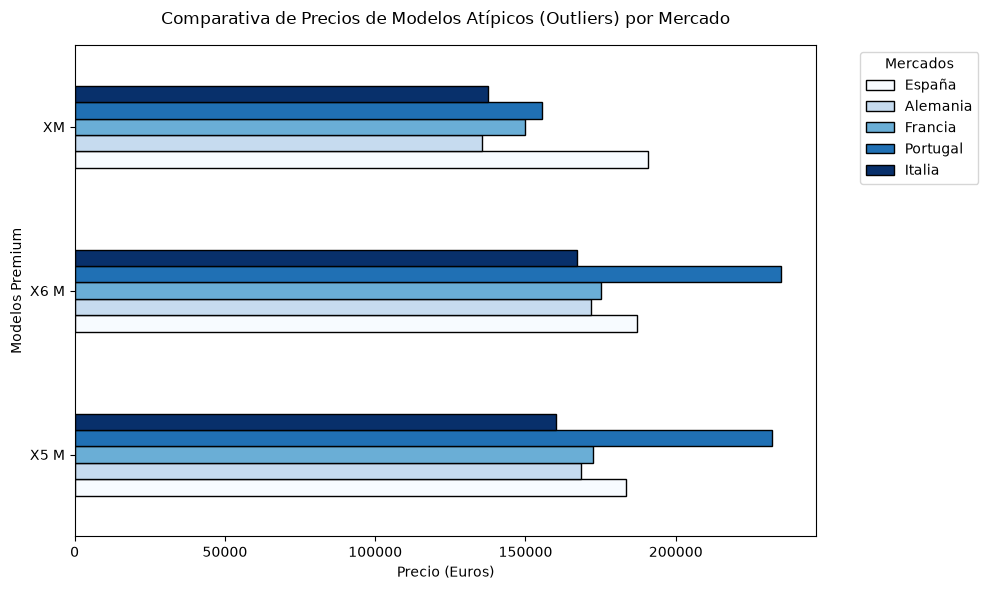

In [33]:
#Obtener la lista única de todos los modelos que son outliers en algún mercado
#Usamos los nombres que detectamos en los análisis estadísticos previos
modelos_outliers = ['X5 M', 'X6 M', 'XM']
df_outliers = df[df['Modelo'].isin(modelos_outliers)]

#Configurar el gráfico de barras horizontales agrupado
#Establecemos el modelo como índice para que actúe de etiqueta en el eje Y
df_outliers.set_index('Modelo').plot(
    kind='barh', 
    figsize=(10, 6), 
    cmap='Blues', # Usa una paleta degradada elegante
    edgecolor='black'
)

#Personalización 
plt.title('Comparativa de Precios de Modelos Atípicos (Outliers) por Mercado', fontsize=12, pad=15)
plt.xlabel('Precio (Euros)', fontsize=10)
plt.ylabel('Modelos Premium', fontsize=10)
plt.legend(title='Mercados', bbox_to_anchor=(1.05, 1), loc='upper left') # Mueve la leyenda fuera para no tapar barras

# Forzar a Matplotlib a recalcular los márgenes para que no se corte el texto
plt.tight_layout()
plt.show()


**15.2. Algunas conclusiones alcanzadas al analizar los outliers**

#Posible análisis de los outliers:

En las cinco columnas hay dos modelos comunes: X5 M y X6 M, que están entre aquellos de mayor precio del catálogo de la marca para el año 2026. Representan, asimismo, parte del nicho de mercado dirigido a obtener la mayor rentabilidad posible dentro de la marca, aunque el número de unidades que se entreguen a los compradores finales
sea mucho más reducido.
Además sus especificaciones técnicas y comerciales se encuentran muy por encima de la media de vehículos más comunes.

#Puntos comunes a ambos:

*   Aparecen reflejados en los outliers por encima del nivel superior en
cualquiera de los cinco países que se han elegido para analizar el catálogo de precios de BMW.
*   Se trata de las versiones más deportivas de sus respectivos modelos base, de ahí que lleven la letra M. Esto hace que los precios puedan llegar incluso a triplicarse.


*   Están englobados en la categoría de SUV premium de gran tamaño. Esto permite a la marca maximizar sus beneficios. Se puede apreciar un sesgo a la derecha muy acusado, pues el IQR asume que pocas unidades concentran unos valores tan altos (superando con creces el precio de sus modelos base)
*   Se deprecian a mucha menos velocidad que los modelos base de los que parten porque su producción es más limitada y, sobre todo, porque la letra M ya designa a otro nicho independiente de mercado.


#Puntos diferenciadores: cada modelo se dirige a un usuario diferente.

*   El BMW X5 M compite con modelos similares de otras marcas, como el Audi Q7 o el Mercedes Benz GLC. Tiene un precio base o de salida que puede llegar a triplicar el precio de un SUV de una marca considerada generalista. Pero si miramos el propio nicho del X5, podrían entrar en juego otros aspectos (técnicos, electrónicos, etc.) que hagan aumentar su precio
*   El X6M aparece como outlier porque se trata de un nicho propio, al cual se le aplicó una estrategia de precio de diseño de nicho, haciendo que el precio final sea todavía más elevado.
Su diseño con silueta similar a modelos coupé y exclusividad respecto a otros modelos de su mismo segmento influye en su precio final.
En consecuencia, debido a lo expuesto en la línea anterior, el X6 superará en precio al X5 aunque éste sea más voluminoso.

Si nos ponemos en el lugar de un cliente potencial, el factor precio, sumado a otros que no se han mencionado en el df (como por ejemplo el
espacio disponible en las plazas traseras, maletero, o simplemente exclusividad) serían muy determinantes a la hora de decidirse por uno u otro.

Al comparar por países podemos ver que, a pesar de compartir mercado, su estructura de salarios y fiscalidad difieren. Aquí llama la atención el outlier tan elevado que presenta Portugal (si miramos el gráfico de caja):


*   Portugal aplica el ISV, un impuesto que penaliza emisiones y cilindrada, haciendo que los precios suban en un porcentaje muy alto. De ahí que Portugal, en líneas generales, muestre los precios más altos del catálogo.
*   Alemania: influyen en el precio final factores como el equipamiento y el sesgo de gama alta.
Se aprecia también la presencia de otras marcas que se fabrican allí y que son competencia directa (Audi, Mercedes Benz, etc.)Mayor poder adquisitivo de la población en general.



*   España e Italia: concentran el tercer cuartil, pero en sentido descendente. Predominan los salarios medianos y la tipología de las ciudades, por lo tanto se aprecia una mayor adquisición de modelos englobados en los segmentos del A al D, principalmente berlinas y compactos.
*   Francia: Su impuesto a los vehículos más contaminantes hacen que sus precios finales se eleven en un porcentaje muy alto.



No obstante, llama la atención que en la columna España, se incluya también el modelo XM: En este punto, una posible interpretación es la alta carga impositiva inherente, sumado al ya de por sí muy elevado precio de este modelo en particular (190.000€). El XM puede ser considerado un nicho propio, dentro del propio nicho de mercado formado por los modelos X (que representan aquellos con algunas aptitudes off road), pues está diseñado desde cero por la division deportiva de la marca, M.

Sin embargo, su volumen de mercado en líneas generales es casi insignificante si se compara con otros modelos del mismo segmento y que concentra el mayor volumen de ventas, como por ejemplo el X1.
En definitiva: El BMW XM podría verse como un outlier puro, pues es un modelo que no tiene un equivalente básico como en el caso (ejemplo) del Serie 3 y el M3.

* Como veremos en la siguiente celda, no se aprecian outliers por debajo del límite inferior, ya que el fabricante impone un precio suelo y los cambios se producen por factores como impuestos o equipamiento extra. 

**15.3 ¿Hay outliers por debajo del limite inferior?**

In [34]:
#Reflejar solamente los outliers que no superan el límite inferior
#(En caso de haberlos)
#Iterar sobre las columnas numéricas por cada mercado:
print("Verificando Outliers inferiores:")
for column in df.select_dtypes(include=np.number).columns:
    Q1= df[column].quantile(0.25)
    Q3= df[column].quantile(0.75)
    IQR= Q3 -Q1
    lower_bound = Q1-1.5*IQR
   
    #Solamente filtramos las columnas con outliers que no superan el límite inferior
    outliers_inferior = df[df[column]<lower_bound]

#Imprimir estado, habiendo corregido errores 
    if not outliers_inferior.empty:
        print(f"\nGráfico de Outliers (solo inferiores) en la columna '{column}':")
        plt.figure(figsize=(10,6))
        plt.bar(outliers_inferior['Modelo'], outliers_inferior[column], color='salmon')
        plt.xlabel('Modelo')
        plt.ylabel(f'Valor en {column}')
        plt.title(f'Outliers (inferiores) detectados en {column}')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()
    else:
        print(f"No se detectaron outliers inferiores en la columna '{column}'.")

Verificando Outliers inferiores:
No se detectaron outliers inferiores en la columna 'España'.
No se detectaron outliers inferiores en la columna 'Alemania'.
No se detectaron outliers inferiores en la columna 'Francia'.
No se detectaron outliers inferiores en la columna 'Portugal'.
No se detectaron outliers inferiores en la columna 'Italia'.


**EXTRA: Representación de outliers con boxplot**

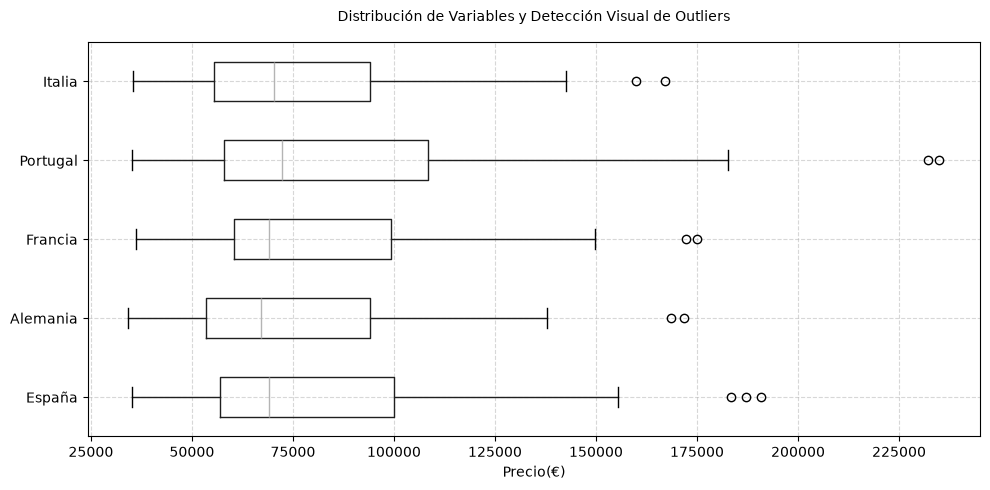

In [35]:
#Representación de los outliers con boxplot

columnas_numericas = df.select_dtypes(include=np.number).columns

#Crear gráfico y columna de caja
plt.figure(figsize=(10, 5))
df.boxplot(column=list(columnas_numericas),vert=False)

#Diseño
plt.title('Distribución de Variables y Detección Visual de Outliers', fontsize=10, pad=15)
plt.xlabel('Precio(€)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

#Mostrar gráfico
plt.tight_layout()
plt.show()



#Análisis del gráfico de caja o boxplot:
- Limite inferior o comienzo de la caja: en términos generales, está representado por el Serie 1, un modelo de tipo compacto. Parte de una media de 30.000€.
- Centro: entre 50.000€ y 65.000€. Aquí se concentran modelos muy variados, desde el X1 (desde 44.000€), pasando por la berlina superventas, el Serie 3 (desde 47.000€) o modelos puramente eléctricos como el iX3, que parte de 69.000€.
- Límite superior: Topa en torno a los 95-100.000€, con modelos considerados más exclusivos, de lujo o de producción muy limitada, como el mencionado anteriormente X5 M, o el Serie 7.

<span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**16. ANÁLISIS DEL MODELO *XM* COMO OUTLIER**</span>


In [36]:
#Filtrar los datos del XM una sola vez para todos los países
#Recorrer lista de países sobre columnas numéricas
data_xm = df[df['Modelo'].str.contains('^XM$', regex=True, na=False)]

if not data_xm.empty:
    print("Análisis de desviación del BMW XM por país:")
    print("=" * 60)
    paises_objetivo = ['España', 'Alemania', 'Francia', 'Portugal', 'Italia']
    
    for pais in paises_objetivo:
        precio_xm = data_xm[pais].values[0]
        
        #Calcular estadísticas básicas del mercado actual
        Q1 = df[pais].quantile(0.25)
        Q3 = df[pais].quantile(0.75)
        IQR = Q3 - Q1
        upper_bound = Q3 + 1.5 * IQR
        
        # Comprobar si el modelo es un outlier en este mercado
        if precio_xm > upper_bound:
            distancia_veces_iqr = (precio_xm - Q3) / IQR
            print(f"País: {pais}")
            print(f"  -> Q3 del mercado: {Q3:,.2f} € | Umbral Outlier: {upper_bound:,.2f} €")
            print(f"  -> Precio del BMW XM: {precio_xm:,.2f} €")
            print(f"  -> Distancia estadística: ¡Supera el Q3 en {distancia_veces_iqr:.2f} veces el IQR!")
        else:
            print(f"País: {pais} -> El BMW XM NO es un outlier superior en este país. Precio: {precio_xm:,.2f} €")
        print("-" * 50)
else:
    print("No se encontró el modelo exacto 'XM' en el catálogo.")


Análisis de desviación del BMW XM por país:
País: España
  -> Q3 del mercado: 100,087.50 € | Umbral Outlier: 164,962.50 €
  -> Precio del BMW XM: 190,900.00 €
  -> Distancia estadística: ¡Supera el Q3 en 2.10 veces el IQR!
--------------------------------------------------
País: Alemania -> El BMW XM NO es un outlier superior en este país. Precio: 135,500.00 €
--------------------------------------------------
País: Francia -> El BMW XM NO es un outlier superior en este país. Precio: 149,850.00 €
--------------------------------------------------
País: Portugal -> El BMW XM NO es un outlier superior en este país. Precio: 155,550.00 €
--------------------------------------------------
País: Italia -> El BMW XM NO es un outlier superior en este país. Precio: 137,500.00 €
--------------------------------------------------


**16.1. Representación gráfica del outlier del XM**

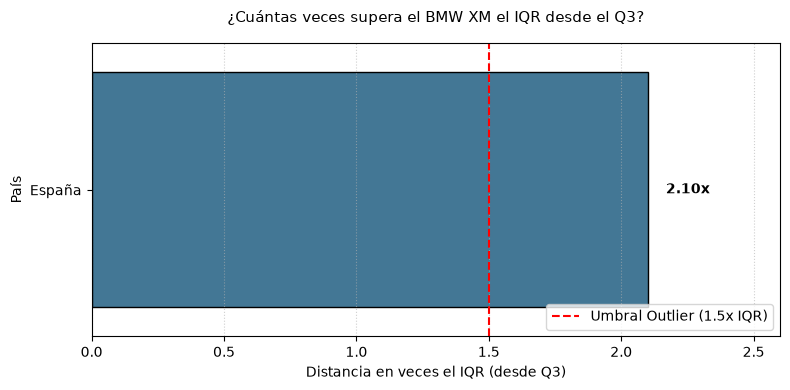

In [37]:
paises_grafico = []
distancias_grafico = []

#Filtrar'XM' una sola vez fuera del bucle 
df_xm_row = df[df['Modelo'].str.contains('^XM$', regex=True, na=False)]

if not df_xm_row.empty:
    paises_a_analizar = ['España', 'Alemania', 'Francia', 'Portugal', 'Italia']

    # Calcular métricas iterando cada país
    for pais in paises_a_analizar:
        country_prices = df[pais]

        Q1 = country_prices.quantile(0.25)
        Q3 = country_prices.quantile(0.75)
        IQR = Q3 - Q1
        upper_bound = Q3 + 1.5 * IQR

        precio_xm = df_xm_row[pais].values[0]

        # Verificar si el precio del XM es un outlier superior
        if precio_xm > upper_bound:
            distancia_veces_iqr = (precio_xm - Q3) / IQR
            paises_grafico.append(pais)
            distancias_grafico.append(distancia_veces_iqr)

#Crear del gráfico (Solo si hay datos de outliers para mostrar)
if paises_grafico:
    plt.figure(figsize=(8, 4))
    
    # Graficar con Seaborn usando los parámetros optimizados
    sns.barplot(
        x=distancias_grafico, 
        y=paises_grafico, 
        palette='mako', 
        hue=paises_grafico, 
        legend=False,
        edgecolor='black'
    )

    # Etiquetas de datos
    for i, valor in enumerate(distancias_grafico):
        plt.text(valor + 0.05, i, f" {valor:.2f}x", va='center', fontweight='bold', fontsize=10)

    # Línea vertical del umbral crítico (1.5x IQR)
    plt.axvline(x=1.5, color='red', linestyle='--', linewidth=1.5, label='Umbral Outlier (1.5x IQR)')
    
    # Personalización y ajustes del límite del eje X y dar espacio al texto
    plt.title('¿Cuántas veces supera el BMW XM el IQR desde el Q3?', fontsize=11, pad=15)
    plt.xlabel('Distancia en veces el IQR (desde Q3)', fontsize=10)
    plt.ylabel('País', fontsize=10)
 
    plt.xlim(0, max(distancias_grafico) + 0.5)
    
    plt.legend(loc='lower right')
    plt.grid(axis='x', linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()
else:
    print("No se encontraron outliers del modelo XM por encima del umbral en los países seleccionados.")


<span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**17. NIVEL DE PRECIO POR MODELOS**</span>

In [38]:
#Crear el gráfico de barras interactivo con Plotly Express
fig = px.bar(
    df,
    x="Alemania",
    y="Modelo",
    orientation="h",
    title="Nivel de Precio por Modelo para Alemania",
    labels={"Modelo": "Modelos", "Alemania": "Precio (€)"},
    template="plotly_white",
)

# Ajustar el color de las barras a 'steelblue' y las dimensiones
fig.update_traces(marker_color='steelblue')
fig.update_layout(width=1000, height=800, bargap=0.3)

# Mostrar el gráfico interactivo (habiendo ordenado precios de mayor a menor)
#Renderizado
fig.update_yaxes(categoryorder="total ascending")
fig.show()

<span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**18. MODELOS MÁS VENDIDOS DE LA GAMA EN ESPAÑA EN EL 2025: X1, X2, X3**</span>


Se calcula que el 80% de dichas ventas tuvieron lugar mediante financiación (Como el programa flexible BMW Select, o a través de renting con BMW Bank) y el 20% restante se pagó al contado.
BMW aplicaba un TIN (tipo de interés nominal) de entre un 4.99 y un 5.99%, y un TAE del 6.67% (datos del año 2025)

Ejemplo: Importe a financiar al adquirir el X3 xDrive 20d, **con un precio de venta de 63990€, como precio al contado**.

- Aporte inicial (Entrada): 19.197€
- Tipo interés nominal (TIN): 7.99%
- Tasa anual equivalente (TAE): 8.96%
- Plazo a pagar de 36 meses: 35 cuotas mensuales de 511,74€ más cuota final.
- Total a financiar: 44940.50€
- Comisión de apertura: 669.61 (1.49%)
- Total a financiar: 44.940,55
- Cuota final: 36.839,53€

¿Cuánto paga el cliente final financiando su compra?






In [39]:
#Para averiguar el total a pagar con financiacion: (precio_final)
#Cuotas mensuales (*35): cuota
#Aporte inicial (aporte_inicial)
#Pago de cuota final (cuota_final)
#Coste total del crédito con intereses (credito_con_intereses): Se resta el total que se ha pagado a plazos
#(Entrada o aporte inicial + (Cuotas mensuales * Meses)+Cuota final) - Precio al contado

#Cuotas mensuales: multiplicar por 35
cuota = 511.74*35
print(f"Cuota a pagar en 35 mensualidades: {cuota}€")

#Para el punto siguiente: Averiguar coste total a pagar y coste del crédito

coste_total = (19197 +(511.74*35)+36839.53)
print(f"Total a pagar con financiación: {coste_total:.2f}€")

#Restamos el precio total obtenido antes menos el precio al contado
al_contado = 63990
coste_credito = (coste_total - al_contado)
print(f"Coste del crédito: {coste_credito:.2f}€")

Cuota a pagar en 35 mensualidades: 17910.9€
Total a pagar con financiación: 73947.43€
Coste del crédito: 9957.43€


**18.1 Representación de la información anterior en un gráfico de barras**

In [40]:
#representación gráfica de los datos anteriores 
# Preparar los datos en un DataFrame con Plotly Express
data = {
    'Modalidad de Pago': ['Financiación (80% ventas)', 'Al Contado (20% ventas)'],
    'Precio (€)': [coste_total, al_contado]
}
df_plot = pd.DataFrame(data)

# Crear el gráfico de barras interactivo con Plotly Express
fig = px.bar(
    df_plot,
    x='Precio (€)',
    y='Modalidad de Pago',
    orientation='h',
    title='Comparación de Precio de Adquisición (Financiado vs. Contado)',
    labels={'Modalidad de Pago': 'Modalidad de Pago', 'Precio (€)': 'Precio (€)'},
    color='Modalidad de Pago',
    color_discrete_map={'Financiación (80% ventas)': '#66b3ff', 'Al Contado (20% ventas)': '#00008B'},
    text='Precio (€)'
)

# Ajustar el formato del texto en las barras a dos decimales con el símbolo del euro
fig.update_traces(texttemplate='%{x:.2f}€', textposition='outside')

# Ajustar el diseño del gráfico
fig.update_layout(
    uniformtext_minsize=8,
    uniformtext_mode='hide',
    yaxis={'categoryorder':'total ascending'} # Ordenar las barras
)

# Mostrar el gráfico interactivo
fig.show()

**Conclusiones**

Al analizar este gráfico, a primera vista puede llamar la atención que el grueso de las ventas de este modelo se concentren en la modalidad de financiación, pero no es una sorpresa.

Razones que llevan a financiar la compra:
- Facilidad de pago
- Preservar la liquidez a medio plazo: al poner su dinero en el banco, pueden reaccionar mejor a un imprevisto, en vez de destinarlo a pagar algo que pierde valor con rapidez (depreciación).
- Incentivos del propio concesionario: aplicar descuentos si se acepta la financiación.  
- Ventajas como ampliación de la garantía de fábrica.
- Es una opción óptima para cualquier cliente que desea acceder a segmentos o categorías superiores y que, pagando al contado, no podrían hacer.  
- Desde el punto de vista del cliente, es una opción que le permite, en caso de quererlo, cambiar a otro modelo distinto entregando el actual (como parte del pago final) o quedárselo.

Razones que llevan a comprar al contado:
- No hay pago de intereses. Solo se paga el precio que se indica.
- Disponibilidad de la cuantía que se pide.
- El cliente puede no dar mayor importancia a la pérdida de valor o depreciación.
- Propiedad absoluta e inmediata desde el primer día.
- Gestión libre del mantenimiento.
- Mayor libertad a la hora de comparar precios del mismo modelo entre concesionarios distintos.


In [41]:
# Diferencia porcentual (%) entre el coste financiado y pago al contado

diferencia_absoluta = coste_total - al_contado
diferencia_porcentual = (diferencia_absoluta / al_contado) * 100

print(f"El coste financiado es un {diferencia_porcentual:.2f}% más caro que el pago al contado.")

El coste financiado es un 15.56% más caro que el pago al contado.


<span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**19. REPERCUSIÓN DEL IVA EN EL PRECIO FINAL POR PAÍSES**</span>

- Gráfico horizontal: tipo impositivo (%) que fija el contexto fiscal. 
- Gráfico lineal comparativo: tomando un precio base y mostrar visualmente el precio REAL debido a dicho impuesto. 

Index(['País', 'IVA (%)', 'precio final'], dtype='str')
df_IVA columns: ['País', 'IVA (%)', 'precio final']


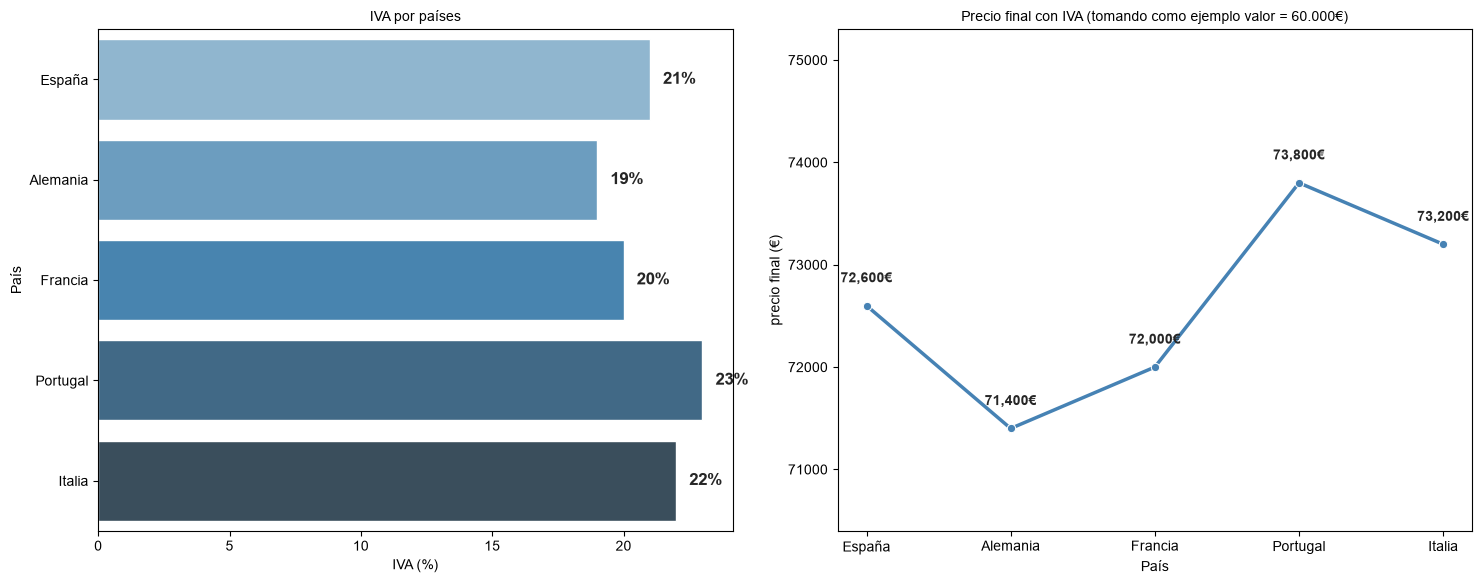

In [42]:
#Tipo de datos: IVA vigente en cada país
datos_IVA = {
    'País': ['España', 'Alemania', 'Francia', 'Portugal', 'Italia'],
    'IVA (%)': [21, 19, 20, 23, 22]
}
#Simulación del impacto en el precio base (ejemplo: 60.000€)
pb = 60000
df_IVA = pd.DataFrame(datos_IVA)
df_IVA['precio final'] = pb * (1 + df_IVA['IVA (%)'] / 100)

#Gráficos: 1 fila, 2 columnas 
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.set_theme(style="whitegrid")

#GRÁFICO 1: IVA POR PAÍSES 
sns.barplot(
    x='IVA (%)',
    y='País',
    data=df_IVA,
    palette='Blues_d',
    hue='País',
    legend=False,
    ax=axes[0]
)
print(df_IVA.columns)

axes[0].set_title('IVA por países', fontsize=10)
axes[0].set_xlabel('IVA (%)', fontsize=10)
axes[0].set_ylabel('País', fontsize=10)

#Añadir etiquetas de texto 
for index, row in df_IVA.iterrows():
    axes[0].text(row['IVA (%)'] + 0.5, 
                 index, f"{row['IVA (%)']:.0f}%",
                 va='center',
                 fontweight='bold')
    
#GRÁFICO 2: Precio final con IVA. Impacto REAL en pvp 

print("df_IVA columns:", df_IVA.columns.tolist())

#Detectar columnas 
x_col = next((c for c in df_IVA.columns if 'país' in c.lower() or 'pais' in c.lower()), None)
possible_y = [c for c in df_IVA.columns if 'precio' in c.lower() or 'final' in c.lower() or 'pvp' in c.lower()]

if x_col is None or not possible_y:
    raise ValueError(f"Column detection failed. columns={df_IVA.columns.tolist()}")

y_col = possible_y[0]

sns.lineplot(
    x=['España','Alemania','Francia','Portugal','Italia'],
    y='precio final',
    data=df_IVA,
    marker='o',
    linewidth=2.5,
    color='steelblue',
    ax=axes[1]
)
    
axes[1].set_title('Precio final con IVA (tomando como ejemplo valor = 60.000€)', fontsize=10)
axes[1].set_xlabel(x_col, fontsize=10)
axes[1].set_ylabel(f'{y_col} (€)', fontsize=10)

# Añadimos el valor exacto a cada punto de la línea (formato correcto)
for index, row in df_IVA.iterrows():
    axes[1].text(
        index, 
        row['precio final'] + 200,  # Súmale 200€ de altura para que no pise el marcador azul
        f"{row['precio final']:,.0f}€", 
        ha='center', 
        va='bottom', 
        fontsize=10, 
        fontweight='bold'
    )
    
#Dar margen superior al eje Y para las etiquetas de texto
axes[1].set_ylim(df_IVA['precio final'].min() - 1000, df_IVA['precio final'].max() + 1500)
    
#Añadir márgenes generales y mostrar gráfico: 
plt.tight_layout()
plt.show()

Algunas conclusiones: 

1. El impuesto sobre valor añadido (IVA) repercute en el precio final: 
En el gráfico de barras podemos ver con claridad que Portugal tiene el IVA general más alto, de un 23%, en contraste con Alemania, que es del 19%. Dicho contraste hace que la diferencia en el precio final (aun partiendo del mismo precio base que hemos tomado como referencia, 60.000€) sea de muchos miles de euros. 
El gráfico de líea confirma dicha relaciópn directa en el precio final: 71400€ de Alemania, contra 73800€ de Portugal. 

2. Portugal muestra el mayor impacto fiscal: el 23% de IVA provoca el valor más elevado, lo que hace que este factor sea muy significativo a la hora de adquirir un modelo que parte de este rango de precio. 

3. Alemania: precio más competitivo: puede traducirse de dos formas: 
- Ventaja competitiva 
- Poder adquisitivo mayor del comprador en productos con un valor similar. 

4. España y Francia muestran pocos cambios, solo que esta última se posiciona como algo más asequible respecto al IVA aplicado en España. 

La conclusion que alcanzamos es que el IVA tiene una repercusión directa y proporcional en el precio final que el consumidor paga por un mismo producto. 



<span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**20. ÍNDICE DE DISPERSIÓN DE PRECIOS: COEFICIENTE DE VARIACIÓN (CV)**</span>

**((CV = σ / μ)x100)**

*   Comparar variabilidad de precios de forma estandarizada entre mercados con diferente moneda o media de precios. Confirmar de manera cuantitativa estas dispersiones.
*   Mostrar el tamaño de la variación de un grupo de datos en relacion a su media.
*   Aquí se fusionará otro DataFrame, que incluirá los precios de los modelos del catálogo en Suiza.
*   Moneda: Franco Suizo (CHF)  

**20.1 Fusionar df para incluir los precios de Suiza**. 

In [43]:
# Cargar archivos
fichero_suiza = pd.read_csv('/Users/adriana/Desktop/ANALISIS CODIGO /Análisis precios BMW/precios_suiza.csv', sep=';')
df_suiza = fichero_suiza.copy()

#Limpiar espacios en los nombres de las columnas
df_suiza.columns = df_suiza.columns.str.strip()

# Muestra en pantalla qué columnas tiene el archivo de Suiza realmente
print("Las columnas reales de precios_suiza son:", list(df_suiza.columns))

# 2. Eliminar cualquier columna existente llamada "Suiza"
columns_to_drop = [col for col in df.columns if 'suiza' in col.lower()]
if len(columns_to_drop) > 0:
    df.drop(columns=columns_to_drop, inplace=True)

# 3. Forzar mapeo automático buscando variaciones (por si se llama 'suiza', 'SUiZA', 'precio suiza')
col_modelo_suiza = next((c for c in df_suiza.columns if 'model' in c.lower()), None)
col_precio_suiza = next((c for c in df_suiza.columns if 'suiza' in c.lower()), None)

if 'Modelo' in df.columns and col_modelo_suiza and col_precio_suiza:
    # Renombramos temporalmente para asegurar el match perfecto
    df_suiza_temp = df_suiza.rename(columns={col_modelo_suiza: 'Modelo', col_precio_suiza: 'Suiza'})
    df = pd.merge(df, df_suiza_temp[['Modelo', 'Suiza']], on='Modelo', how='left')
    print("¡Fusión lograda con éxito buscando nombres aproximados!")
else:
    print("No se pudo fusionar de forma automática.")
    if not col_modelo_suiza: print("- No encontramos nada parecido a 'Modelo' en tu archivo de Suiza.")
    if not col_precio_suiza: print("- No encontramos nada parecido a 'Suiza' en tu archivo de Suiza.")

print("\nResultado:")
display(df.head())

Las columnas reales de precios_suiza son: ['Unnamed: 0', 'Modelo', 'Precios para Suiza (Franco Suizo CHF)']
¡Fusión lograda con éxito buscando nombres aproximados!

Resultado:


,Modelo,España,Alemania,Francia,Portugal,Italia,Suiza
0,Serie 1 116i,35150,34250,36200,35200,35500,41700
1,Serie 1 118d,40250,39350,38900,41650,40210,47300
2,Serie 2 Coupe 218i,50300,46300,60925,50450,46200,58200
3,Serie 2 coupe 220d,56500,53400,61540,59450,54200,61200
4,Serie 2 Gran Coupe 218i,38650,37750,50250,38700,39000,44900


**20.2 Cálculo del coeficiente de variación:**

- Se trata de comprobar la dispersión de precios 
- NOTA: Tener en cuenta la diferencia de divisas (CHF vs Eur)
- Tomar como referencia: 1 CHF = 0.94€ 
- La columna "Suiza" marca los precios en CHF, mientras que "Suiza_Euro" los marca en Euros 

In [44]:
#Definir la tasa de conversión
#Nota: Si 1 CHF = 0.94€, al multiplicar el precio en francos por 0.94 se obtendrá el valor en euros.

tasa_eur_chf = 0.94

#Sobrescribimos la columna 'Suiza_Euro' SIEMPRE desde la columna origen 'Suiza'
# Obtener los precios originales en CHF
if 'Suiza' in df.columns:
    precios_suiza_chf = df['Suiza']
else:
    precios_suiza_chf = df['Modelo'].map(
        df_suiza.set_index('Modelo')[col_precio_suiza]
    )

df['Suiza_Euro'] = pd.to_numeric(precios_suiza_chf, errors='coerce')

#Conversión matemática
df['Suiza_Euro'] = (df['Suiza_Euro'] / tasa_eur_chf).fillna(0).astype(int)

# Evitar KeyError si aún no existe la columna 'Suiza' en df
if 'Suiza' in df.columns:
    precios_suiza_chf = pd.to_numeric(df['Suiza'], errors='coerce')
else:
    mapeo_suiza = df_suiza.set_index('Modelo')[col_precio_suiza].astype(float)
    precios_suiza_chf = df['Modelo'].map(mapeo_suiza)

# Crear/actualizar la columna convertida a euros
df['Suiza_Euro'] = (precios_suiza_chf / tasa_eur_chf).round(2)

# Mostrar solo columnas que realmente existen
cols_a_mostrar = ['Modelo', 'Suiza_Euro']
if 'Suiza' in df.columns:
    cols_a_mostrar.insert(1, 'Suiza')

display(df[cols_a_mostrar].head())


,Modelo,Suiza,Suiza_Euro
0,Serie 1 116i,41700,44361.70
1,Serie 1 118d,47300,50319.15
2,Serie 2 Coupe 218i,58200,61914.89
3,Serie 2 coupe 220d,61200,65106.38
4,Serie 2 Gran Coupe 218i,44900,47765.96


In [45]:
#2. Coeficiente de variación CV

#Cargar df principal (para que no haya columnas de índice sin nombre)
df = pd.read_csv('/Users/adriana/Desktop/ANALISIS CODIGO /Análisis precios BMW/bmw_prices_2026.csv', sep=';')
df.columns = df.columns.str.strip()

#Cargar archivo csv de precios de Suiza e ignorar columna de índice
df_suiza = pd.read_csv('/Users/adriana/Desktop/ANALISIS CODIGO /Análisis precios BMW/precios_suiza.csv', sep=';', index_col=0)
df_suiza.columns = df_suiza.columns.str.strip()


#Eliminar cualquier columna existente llamada "Suiza" en el df principal
columns_to_drop_cv = [col for col in df.columns if 'suiza' in col.lower()]
if columns_to_drop_cv:
    df = df.drop(columns=columns_to_drop_cv)

#Fusionar y traer la columna de precios de Suiza
#Asegurarse de que cada modelo mantiene su correspondiente precio
col_precio_suiza = 'Precios para Suiza (Franco Suizo CHF)'
df = pd.merge(df, df_suiza[['Modelo', col_precio_suiza]], on='Modelo', how='left')

#Convertir francos suizos a euros tomando como referencia. 1CHF = 0.94€
tasa_eur_chf = 0.94 
df['Suiza_Euro'] = pd.to_numeric(df[col_precio_suiza], errors='coerce') / tasa_eur_chf
df['Suiza_Euro'] = df['Suiza_Euro'].fillna(0).astype(int)

#Eliminar la columna original (en francos suizos) y dejar solo valores en €
df = df.drop(columns=[col_precio_suiza])

#Desviación estándar y media 
std_paises = df.select_dtypes(include='number').std()
mean_paises = df.select_dtypes(include='number').mean()

#Coeficiente de variación o desviación relativa CV
cv_paises = (std_paises / mean_paises) *100
print("Coeficiente de variación por país (%):")
print(cv_paises.sort_values(ascending=False).round(2))

Coeficiente de variación por país (%):
Portugal      47.52
España        43.66
Alemania      39.59
Italia        39.18
Suiza_Euro    38.40
Francia       38.14
dtype: float64


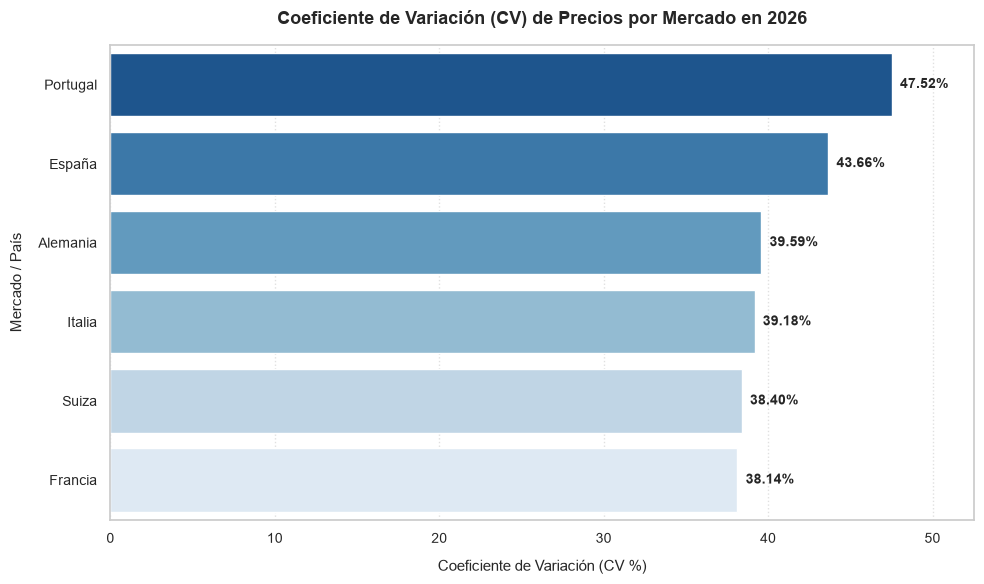

In [46]:
#Limpiar df eliminando "coluna fantasma unnamed"
columnas_basura = [col for col in df.columns if 'unnamed' in col.lower() or 'index' in col.lower()]
if columnas_basura:
    df = df.drop(columns=columnas_basura)
    
#Recalcular las métricas limpias con todos los países del proyecto definiendo cada uno de ellos 
paises_estudio = ['España', 'Alemania', 'Francia', 'Portugal', 'Italia', 'Suiza_Euro']
df_numerico = df[paises_estudio].select_dtypes(include='number')

std_paises = df_numerico.std()
mean_paises = df_numerico.mean()
cv_paises = (std_paises / mean_paises) * 100

#Preparar el DataFrame para el gráfico
df_cv = cv_paises.reset_index()
df_cv.columns = ['Pais', 'Coeficiente de Variación (%)']
df_cv['Pais'] = df_cv['Pais'].replace('Suiza_Euro', 'Suiza')

#Ordenar valores para una mejor visualización de mayor a menor dispersión
df_cv = df_cv.sort_values(by='Coeficiente de Variación (%)', ascending=False)

#Dibujar el gráfico corporativo
plt.figure(figsize=(10, 6))
sns.barplot(
    data=df_cv, 
    x='Coeficiente de Variación (%)', 
    y='Pais', 
    palette='Blues_r', # Muestra un degradado azul elegante de más oscuro a más claro
    hue='Pais',
    legend=False
)

#Añadir los valores exactos al final de cada barra para que sea más legible en tu memoria
for index, row in enumerate(df_cv.itertuples()):
    plt.text(row._2 + 0.5, index, f"{row._2:.2f}%", va='center', fontweight='bold', fontsize=10)

plt.title('Coeficiente de Variación (CV) de Precios por Mercado en 2026', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Coeficiente de Variación (CV %)', fontsize=11, labelpad=10)
plt.ylabel('Mercado / País', fontsize=11, labelpad=10)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='x', linestyle=':', alpha=0.6)

# Dar margen extra en el eje X para que quepan las etiquetas de texto
plt.xlim(0, df_cv['Coeficiente de Variación (%)'].max() + 5)

plt.tight_layout()
plt.show()



Análisis del coeficiente de variación: 
El gráfico anterior muestra la dispersión relativa de los precios de los modelos de BMW en cada país.
Un coeficiente de variación alto indica una dispersión mayor o variabilidad en los precios. Factores que intervienen: 
- Estrategias de mercado 
- Modelos de más lujo que elevan la media 

**Portugal** tiene el coeficiente de variación más alto, y ello sugiere una mayor heterogeneidad en los precios de sus modelos en comparación con otros países.
España y Suiza también muestran una dispersión considerable, mientras que Francia e Italia presentan una variabilidad ligeramente menor. La 'Suiza' original (con sus precios en CHF) tiene un CV muy similar a Francia e Italia, lo cual es coherente si las diferencias de precio se mantienen en ambas divisas. 

<span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**21. CLASIFICACIÓN POR GAMAS DE ACCESO**</span>

Objetivo: identificar patrones de fijación de precios (*pricing*)

In [47]:
##Unificar df: para definir el conjunto de columnas numéricas (en €)
col_paises = ['España','Alemania','Francia','Portugal','Italia','Suiza_Euro']

#Función de cálculo del CV global por fila 
def calculo_cv_global(row):
    #Extraer precios de cada fila para los países escogidos
    precios = [row[col] for col in col_paises if col in row.index]
    #Filtrar nulos (si los hay)
    precios_validos = [p for p in precios if not pd.isna(p) and p>0]
    if len(precios_validos) <2:
        return np.std(precios_validos, ddof=1)/np.mean(precios_validos)

#Coeficiente de Variación porcentual muestral (ddof=1) o poblacional (ddof=0)
    return (np.std(precios_validos, ddof=0) / np.mean(precios_validos)) * 100

df["CV_global"] = df.apply(calculo_cv_global, axis=1)

In [48]:
#Regla de negocio: 
#2. Segmentar catálogo por nivel de dispersión: regla de negocio 
def segmentacion_estrategia(cv):
    if pd.isna(cv):
        return "No hay datos suficientes"
    elif cv < 3.0:
        return "Estrategia global estándar: dispersión baja"
    elif cv <= 8.0:
        return "Adaptación regional moderada: dispersión media"
    else:
        return "Asimetría de precios alta: arbitraje potencial"


# Aplicar segmentación (no sobrescribir con el valor numérico)
df['segmento_precio'] = df['CV_global'].apply(segmentacion_estrategia)

#Convertir precios de suiza en números enteros
# Asegurar que exista 'Suiza_Euro' en EUR y convertirla a entero nullable
df['Suiza_Euro'] = df['Suiza_Euro'].round().astype('Int64')

#Conteo de modelos por segmentos: 
print("Distribución de modelos de BMW por segmentos de precio:")
print(df['segmento_precio'].value_counts())
print("-" * 60)

#mostrar resultado
cols = ['Modelo', 'CV_global', 'segmento_precio'] + col_paises
display_cols = [c for c in cols if c in df.columns]
display(df[display_cols])

Distribución de modelos de BMW por segmentos de precio:
segmento_precio
Asimetría de precios alta: arbitraje potencial    45
Adaptación regional moderada: dispersión media    30
Estrategia global estándar: dispersión baja        3
Name: count, dtype: int64
------------------------------------------------------------


,Modelo,CV_global,segmento_precio,España,Alemania,Francia,Portugal,Italia,Suiza_Euro
0,Serie 1 116i,9.353642,Asimetría de precios alta: arbitraje potencial,35150,34250,36200,35200,35500,44361
1,Serie 1 118d,9.369183,Asimetría de precios alta: arbitraje potencial,40250,39350,38900,41650,40210,50319
2,Serie 2 Coupe 218i,12.168700,Asimetría de precios alta: arbitraje potencial,50300,46300,60925,50450,46200,61914
3,Serie 2 coupe 220d,7.070303,Adaptación regional moderada: dispersión media,56500,53400,61540,59450,54200,65106
4,Serie 2 Gran Coupe 218i,11.917980,Asimetría de precios alta: arbitraje potencial,38650,37750,50250,38700,39000,47765
...,...,...,...,...,...,...,...,...,...
73,X5 M60i xDrive,10.120165,Asimetría de precios alta: arbitraje potencial,128850,120000,122000,154650,119300,143617
74,X6 M,12.451361,Asimetría de precios alta: arbitraje potencial,187050,171900,175000,235000,167000,205957
75,X6 M60i xDrive,12.355776,Asimetría de precios alta: arbitraje potencial,134450,123500,123000,157550,123100,164148
76,X7 M60i xDrive,11.783110,Asimetría de precios alta: arbitraje potencial,155400,138000,140000,182550,142500,179893


<span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**22. SEGMENTACIÓN DE MÁRGENES POR TIPO DE CARROCERÍA: SUV VS BERLINAS**</span>

*Tomamos como referencia neutral Suiza*

In [49]:
# 1. Crear función para clasificar carrocerías (Lógica de negocio)
def categoria_carroceria(modelo):
    if 'X' in str(modelo) or 'XM' in str(modelo):
        return 'SUV'
    else: 
        return 'Berlina'

# 2. Aplicar la categorización creando la columna como un String correcto
df['categoria_carroceria'] = df['Modelo'].apply(categoria_carroceria)

# 3. FILTRAR los valores mayores a cero directamente sobre nuestra columna unificada 'Suiza_Euro'
# Esto elimina los ceros basura de modelos que no estaban en el catálogo suizo
df_valid_suiza = df[df['Suiza_Euro'] > 0]

# 4. Calcular los estadísticos descriptivos usando ÚNICAMENTE el DataFrame filtrado (df_valid_suiza)
analisis_suiza = (
    df_valid_suiza.groupby('categoria_carroceria')['Suiza_Euro']
      .agg(['mean', 'min', 'max', 'count'])
)

# 5. Renombrar las columnas de forma definitiva para el reporte
analisis_suiza.columns = [
    'Precio medio (€)',
    'Precio mínimo (€)',
    'Precio máximo (€)',
    'Número de modelos'
]

print("Análisis de margen y precio por tipo de carrocería en Suiza (precios en €):")
display(analisis_suiza.round(2))



Análisis de margen y precio por tipo de carrocería en Suiza (precios en €):


,Precio medio (€),Precio mínimo (€),Precio máximo (€),Número de modelos
categoria_carroceria,,,,
Berlina,86093.12,44361,158510,50
SUV,106018.5,55531,205957,28


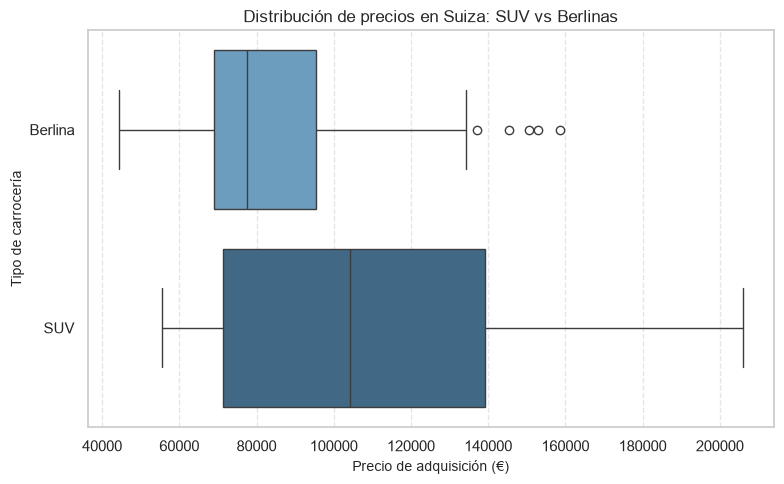

In [50]:
#Representación gráfica del apartado anterior

import seaborn as sns 
import matplotlib.pyplot as plt 

plt.figure(figsize=(8, 5))

# Filtrar valores nulos o iguales a cero
df_filtrado = df[df['Suiza_Euro'].notna() & (df['Suiza_Euro'] > 0)]

sns.boxplot(
    data=df_filtrado,
    x='Suiza_Euro',
    y='categoria_carroceria',
    palette='Blues_d',
    hue='categoria_carroceria',
    legend=False
)

plt.title('Distribución de precios en Suiza: SUV vs Berlinas')
plt.xlabel('Precio de adquisición (€)', fontsize=10)
plt.ylabel('Tipo de carrocería', fontsize=10)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()



Al escoger Suiza como referencia neutral (ya que no pertenece a la Eurozona), es posible ver de una forma muy clara la estrategia de precios que está siguiendo la marca de cara al 2026:

- Dominancia de la gama SUV: la media de la categoría SUV se posiciona de forma muy destacable por encima de las berlinas. Lo que demuestra que BMW aprovecha la alta demanda que experimenta este segmento para fijar unos precios de salida más elevados y recogiendo un mayor beneficio por unidad vendida. 
- Price floor: suelo de precio. El precio mínimo de la categoría SUV comienza en una posición más elevada que el de las berlinas. El mercado suizo presenta un poder adquisitivo muy alto, lo que hace que el coste de entrada a la gama SUV lo sea también, haciendo que las versiones que no tienen extras no se comercialicen aquí. 
- Dispersión en techo de gama: destaca la distancia entre el máximo y mínimo de los SUV, que se ve reforzada por modelos de alto rendimiento (X5 M, X6 M, XM). Suiza tiene a su favor pensalizaciones menos agresivas por cilindrada, y esto la convierte en un escenario propicio para vender SUV de gama alta, y conviertiendo este segmento en el motor principal de la firma en este país. 

**22.1 Medir impacto de los modelos de carrocería familiar o Touring**

In [51]:
#Identificar todos los modelos que contengan la denominación Touring en su nombre: 
#Para ello creamos una columna booleana: permite identificar si el modelo es Touring o no 
df['Es_Touring']=df['Modelo'].str.contains('Touring', case=False, na=False)

#Filtrar valores >0 de la columna 'Suiza_Euro'
df_valid_touring = df[df['Suiza_Euro'] > 0]

#3. Agrupación y cálculo de métricas básicas para ver el impacto financiero real
analisis_touring = df_valid_touring.groupby('Es_Touring')['Suiza_Euro'].agg(['mean', 'max', 'min', 'count'])
analisis_touring.columns = ['Precio medio (€)','Precio maximo (€)', 'Precio minimo (€)', 'Numero de modelos']

#4. Índice visual 
analisis_touring.index = ['Resto de catalogo', 'Modelos touring']
print('Impacto económico de la gama Touring en Suiza (€)')
print(analisis_touring.round(2))

#Desviación porcentual 
precio_medio_touring = analisis_touring.loc['Modelos touring', 'Precio medio (€)']
precio_medio_resto = analisis_touring.loc['Resto de catalogo', 'Precio medio (€)']
diferencia_porcentual = ((precio_medio_touring - precio_medio_resto) / precio_medio_resto) * 100
print(f"Los modelos Touring se sitúan un {diferencia_porcentual:.2f}% por encima o debajo del precio medio del catálogo.")


Impacto económico de la gama Touring en Suiza (€)
                   Precio medio (€)  Precio maximo (€)  Precio minimo (€)  \
Resto de catalogo          94098.71             205957              44361   
Modelos touring             87446.2             145319              66808   

                   Numero de modelos  
Resto de catalogo                 68  
Modelos touring                   10  
Los modelos Touring se sitúan un -7.07% por encima o debajo del precio medio del catálogo.


Suiza y algunos países que comprenden la zona centro y norte del continente europeo representan un apmplio porcentaje de las ventas de vehículos de carrocería familiar, designados por BMW con el nombre Touring. Las familias con alto poder adquisitivo suelen preferir este tipo de carrocería antes que un SUV. 

Algunos factores a destacar: 
- *Corporate Sales* o venta de flotas: En Suiza, la carrocería Touring es destacable en flotas de empresa de alta dirección. 
- Al incluir todos los tipos de motorización, podemos verificar si la estrategia "Power choice" que aplica BMW, es decir, ofrecer el mismo modelo con motores diferentes, altera el precio final del mismo o si el coste final se mantiene estable, forzando la 'transición' a modelos puramente eléctricos con equipamiento sólo de serie. 


**22.2 Comparativa de precios: SUV vs. Touring**

*Objetivo: comprobar si BMW lanza los modelos Touring aun precio inferior a los SUV con el objetivo de captar clientes que buscan espacio sin penalizar autonomía y reducir emisiones globales.*


In [52]:
#Asegurar la columna de precios en Euros usando la variable 'Suiza_Euro'
# Si por algún motivo no existe, la mapeamos desde 'Suiza' usando la tasa de 0.94
tasa_eur_chf = 0.94

if 'Suiza_Euro' not in df.columns:
    if 'Suiza' in df.columns:
        df['Suiza_Euro'] = pd.to_numeric(df['Suiza'], errors='coerce') / tasa_eur_chf
    elif 'df_suiza' in globals():
        col_precio_suiza = 'Precios para Suiza (Franco Suizo CHF)'
        mapeo_suiza = df_suiza.set_index('Modelo')[col_precio_suiza]
        df['Suiza_Euro'] = df['Modelo'].map(mapeo_suiza).astype(float) / tasa_eur_chf
    else:
        raise KeyError("No existe ninguna columna de precios de Suiza para realizar el análisis.")
else:
    df['Suiza_Euro'] = pd.to_numeric(df['Suiza_Euro'], errors='coerce')

#Condiciones para segmentar las carrocerías
def segmentar_espacio(modelo):
    modelo_str = str(modelo).strip()
    if 'Touring' in modelo_str:
        return 'Gama Touring (Familiar)'
    elif 'X' in modelo_str or 'XM' in modelo_str:
        return 'Gama SUV (Gama X / iX)'
    else:
        return 'Otros (Berlinas / Deportivos)'

#Aplicar la segmentación
df['Segmento_Espacio'] = df['Modelo'].apply(segmentar_espacio)

#Eliminar valores nulos (NaN) o ceros (0)
# Esto garantiza que el precio mínimo ('min') busque solo valores reales mayores a cero.

df_comparativa = df[
    df['Segmento_Espacio'].isin(['Gama Touring (Familiar)', 'Gama SUV (Gama X / iX)']) & 
    (df['Suiza_Euro'].notna()) & 
    (df['Suiza_Euro'] > 0)
]

#Calcular métricas financieras clave usando la columna limpia 'Suiza_Euro'
comparar_precios = df_comparativa.groupby('Segmento_Espacio')['Suiza_Euro'].agg(['mean', 'min', 'max', 'count'])
comparar_precios.columns = ['Precio Medio (€)', 'Precio Mínimo (€)', 'Precio Máximo (€)', 'Muestra (Modelos)']

print("Comparación de precios SUV vs Touring para Suiza (Datos Corregidos):")
print("=" * 70)
print(comparar_precios.round(2))
print("-" * 70)

#Calcular la diferencia (%) en el precio medio de entrada de la marca
precio_medio_suv = comparar_precios.loc['Gama SUV (Gama X / iX)', 'Precio Medio (€)']
precio_medio_touring = comparar_precios.loc['Gama Touring (Familiar)', 'Precio Medio (€)']
ahorro_porcentual = ((precio_medio_suv - precio_medio_touring) / precio_medio_suv) * 100

print(f"💡 Los modelos Touring son, de media, un {ahorro_porcentual:.2f}% más económicos que la gama SUV.")
print("=" * 70)



Comparación de precios SUV vs Touring para Suiza (Datos Corregidos):
                         Precio Medio (€)  Precio Mínimo (€)  \
Segmento_Espacio                                               
Gama SUV (Gama X / iX)           106018.5              55531   
Gama Touring (Familiar)           87446.2              66808   

                         Precio Máximo (€)  Muestra (Modelos)  
Segmento_Espacio                                               
Gama SUV (Gama X / iX)              205957                 28  
Gama Touring (Familiar)             145319                 10  
----------------------------------------------------------------------
💡 Los modelos Touring son, de media, un 17.52% más económicos que la gama SUV.


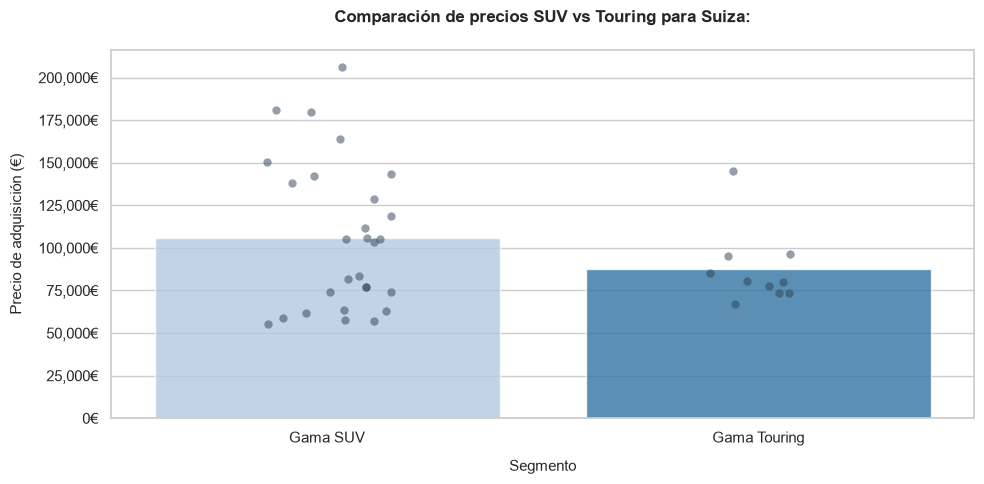

In [53]:
from matplotlib import ticker 

#Configurar estilo básico del gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))

#Asegurar que solo trabajamos con modelos que tienen precios reales en Suiza
df_grafico = df[df['Suiza_Euro'] > 0].copy()

#Crear clasificación para el gráfico 
def clasificar_modelo_grafico(modelo):
    modelo_str = str(modelo).strip()
    if 'Touring' in modelo_str:
        return 'Gama Touring'
    elif 'X' in modelo_str or 'XM' in modelo_str:
        return 'Gama SUV'
    else:
        return 'Otros'

df_grafico['Segmento_Limpio'] = df_grafico['Modelo'].apply(clasificar_modelo_grafico)

#Filtrar la muestra para quedarnos únicamente con SUV y Touring
df_grafico = df_grafico[df_grafico['Segmento_Limpio'].isin(['Gama SUV', 'Gama Touring'])]

#Ordenar las categorías en el eje X
ordenar_categorias = ['Gama SUV', 'Gama Touring']

#Dibujar gráfico de barras para ver las medias
sns.barplot(
    data=df_grafico, 
    x='Segmento_Limpio',
    y='Suiza_Euro',
    order=ordenar_categorias,
    palette=['#1f77b4', '#aec7e8'],
    alpha=0.80,
    errorbar=None,
    hue='Segmento_Limpio',
    legend=False
)

#Superponer los puntos para visualizar la distribución individual y los límites
sns.stripplot(
    data=df_grafico, 
    x='Segmento_Limpio',
    y='Suiza_Euro',
    order=ordenar_categorias,
    color='#2c3e50',
    size=6,
    jitter=0.15,
    alpha=0.5  
)

#Personalización de etiquetas y títulos
plt.title('Comparación de precios SUV vs Touring para Suiza:', fontsize=12, fontweight='bold', pad=20)
plt.xlabel('Segmento', fontsize=11, labelpad=10)
plt.ylabel('Precio de adquisición (€)', fontsize=11, labelpad=10)

#Formatear el eje Y con separador de miles 
plt.gca().yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}€'))
plt.tight_layout()
plt.show()




Factores de análisis: 

- Precio de acceso (min): en la gama Touring parte de un precio más bajo, comenzando por el Serie 3 Touring. Por contra, en la gama SUV los precios se muestran más escalonados, siendo los modelos de acceso el X1 y X2. Sin embargo, el precio escala de manera más rápida en los modelos X3 y X5. Si tomamos en cuenta el impacto en la decisión de compra, los Touring ofrecen espacio a un coste de entrada menor. 
- Precio medio (min): los modelos Touring muestran precios muy competitivos en gamas medias y altas, representadas por las series 3 y 5 Touring. En cambio, el precio de los SUV se dispara con modelos como el X7 o el XM. Aquí el SUV tiende a aumentar su coste por factores percibidos (éxito, posición social elevada), mientras que el Touring se percibe como más "tradicional". 
- Eficiencia: los Touring, por diseño, presentan menor resistencia aerodinámica, y en los modelos eléctricos hay mayor autonomía real. En los SUV sucede lo contrario debido a su mayor altura, siendo menos eficientes energéticamente. Por tanto: un Touring va a dar un mejor coste de total de propiedad, ya que utiliza mejor los recursos energéticos.  

<span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**23. ÍNDICE DE ARBITRAJE**</span>

*En el caso de este análisis, se calcula con el objetivo de saber si a un comprador le compensa viajar a un país o a otro basándose en la brecha de precios existente.* 

In [54]:
#Definir la lista definitiva de los mercados europeos homologados en Euros
columnas_precios = ['España', 'Alemania', 'Francia', 'Portugal', 'Italia', 'Suiza_Euro']

#Reemplazar ceros por NaN para que las funciones .max() y .min(). Ignorar países donde un modelo concreto no se venda (si lo hay) 
df_precios_validos = df[columnas_precios].replace(0, np.nan)

#Obtener precios máximos y mínimos absolutos reales por cada modelo 
df['Max_Precio_EUR'] = df_precios_validos.max(axis=1)
df['Min_Precio_EUR'] = df_precios_validos.min(axis=1)

#Calcular la brecha porcentual de oportunidad de arbitraje real
df['brecha_arbitraje_%'] = ((df['Max_Precio_EUR'] - df['Min_Precio_EUR']) / df['Min_Precio_EUR']) * 100

#Extraer los países exactos donde se registran precios extremos
df['Pais_Min'] = df_precios_validos.idxmin(axis=1)
df['Pais_Max'] = df_precios_validos.idxmax(axis=1)

#Seleccionar y ordenar los cinco modelos con mayor potencial de arbitraje
arbitraje = (
    df.sort_values(by='brecha_arbitraje_%', ascending=False)
      [['Modelo', 'Pais_Min', 'Min_Precio_EUR', 'Pais_Max', 'Max_Precio_EUR', 'brecha_arbitraje_%']]
      .head(5)
)

#redondeo de valores numéricos
arbitraje['Min_Precio_EUR'] = arbitraje['Min_Precio_EUR'].round(2)
arbitraje['Max_Precio_EUR'] = arbitraje['Max_Precio_EUR'].round(2)
arbitraje['brecha_arbitraje_%'] = arbitraje['brecha_arbitraje_%'].round(2)

#Limpiar etiqueta técnica de 'Suiza_Euro' a 'Suiza' para el texto final
arbitraje['Pais_Min'] = arbitraje['Pais_Min'].replace('Suiza_Euro', 'Suiza')
arbitraje['Pais_Max'] = arbitraje['Pais_Max'].replace('Suiza_Euro', 'Suiza')

print('Los cinco modelos con mayor brecha de precio en Europa:')
print(arbitraje.to_string(index=False))



Los cinco modelos con mayor brecha de precio en Europa:
              Modelo Pais_Min  Min_Precio_EUR Pais_Max  Max_Precio_EUR  brecha_arbitraje_%
  Serie 4 coupe 420d Alemania           56700    Suiza           95531               68.49
        Serie 3 320i Alemania           47000    Suiza           68936               46.67
                X5 M   Italia          160000 Portugal          232050               45.03
        Serie 3 318d   España           50200    Suiza           71702               42.83
Serie 3 Touring 318d   España           52200    Suiza           73723               41.23


Posibles motivos para la enorme brecha de precios (mostrada en columna brecha_arbitraje_% ):
- Políticas impositivas de cada país: En el caso de Francia, a través de ayudas estatales como Bonus Écologique, se fuerza a las marcas a reducir el precio base para que el cliente pueda acceder a esta ayuda. No obstante, en países como España, o en otros mercados donde ciertos modelos se venden con un equipamiento de serie cerrado, el precio aumenta. 
- Factor híbrido-enchufable: aquí destacan dos modelos, el X1 xDrive 25e y Serie 2 Active Tourer 225e, que muestran unas brechas del 193% y el 127% aproximadamente. Ambos modelos comparten la misma plataforma energética. Debido a las normativas de emisiones de cada país, los precios se alteran para compensar los impuestos, o para que el cliente haga una configuración a su gusto. 
- Pricing geográfico por demanda (Elasticidad estacional): viene representada por el Serie 4 Cabrio 420i, con una brecha superior al 131%. En los mercados del sur o mediterráneos (en los que se engloban España, Italia y Portugal), hay una mayor disposición a pagar por un modelo cabrio, lo cual permite a la marca exprimir el margen en los países con climás más cálidos, y haciendo que el precio se eleve de forma considerable. Sin embargo, en mercados del centro o norte de Europa, este tipo de coches es de capricho, con una menor demanda y politicas de descuento agresivas.
- Lujo insensible al precio: represnetado por el X5 M. Un SUV de altas prestaciones y alma de coche de carreras, donde el precio máximo (232.050€) duplica al mínimo. El cliente en este caso no presta atención al precio (baja elasticidad). Países como Portugal aplican tasas muy fuertes a los motores con gran cilindrada (el BMW X5 M tiene ocho cilindros), elevando el coste a más de 232.000€. Esto refleja un claro contraste con mercados como el suizo, donde el precio se mantiene en 111.000€. 

<span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**24. OUTLIERS EN MERCADO SUIZO**</span>

*Al ser un mercado con varias particularidades (moneda propia, CHF, y economía caracterizada por rentas muy altas) es esencial conocer sus bases.
Para unificar el bloque desde el punto de vista de las divisas, se ha utilizado la columna Suiza_Euro, con los precios convertidos de francos suizos (CHF) a Euros.
También se usará esta columna para filtrar solamente los valores mayores de cero, para evitar (de haberlos) aquellos modelos que no se comercializan en este país. * 

In [56]:
import numpy as np
import pandas as pd

# 1. Definir la columna de Suiza en euros
col_suiza = 'Suiza_Euro'

# 2. Filtrar para asegurar que calculamos sobre datos válidos (mayores a cero y no nulos)
df_suiza_outliers = df[(df[col_suiza].notna()) & (df[col_suiza] > 0)].copy()

# 3. Calcular Cuartiles (Q1 y Q3) y el IQR
Q1_ch = df_suiza_outliers[col_suiza].quantile(0.25)
Q3_ch = df_suiza_outliers[col_suiza].quantile(0.75)
IQR_ch = Q3_ch - Q1_ch

# 4. Calcular los límites (Vallas de Tukey)
limite_inferior_ch = Q1_ch - 1.5 * IQR_ch
limite_superior_ch = Q3_ch + 1.5 * IQR_ch

print("MÉTRICAS DEL RANGO INTERCUARTÍLICO (IQR) - SUIZA (€):")
print("-" * 60)
print(f"-> Q1 (Percentil 25 - Entrada): {Q1_ch:,.2f} €")
print(f"-> Q3 (Percentil 75 - Gama Alta): {Q3_ch:,.2f} €")
print(f"-> IQR (Rango Intercuartílico): {IQR_ch:,.2f} €")
print(f"-> Umbral Crítico Superior (Outliers): {limite_superior_ch:,.2f} €")
print("=" * 60)

# 5. Filtrar y mostrar los Outliers Superiores reales
outliers_suiza = df_suiza_outliers[df_suiza_outliers[col_suiza] > limite_superior_ch][['Modelo', col_suiza]]

if not outliers_suiza.empty:
    print("🚨 MODELOS DETECTADOS COMO OUTLIERS SUPERIORES EN SUIZA:")
    print(outliers_suiza.sort_values(by=col_suiza, ascending=False).to_string(index=False))
else:
    print("✅ No se detectaron outliers superiores en el mercado suizo.")



MÉTRICAS DEL RANGO INTERCUARTÍLICO (IQR) - SUIZA (€):
------------------------------------------------------------
-> Q1 (Percentil 25 - Entrada): 69,042.50 €
-> Q3 (Percentil 75 - Gama Alta): 105,638.50 €
-> IQR (Rango Intercuartílico): 36,596.00 €
-> Umbral Crítico Superior (Outliers): 160,532.50 €
🚨 MODELOS DETECTADOS COMO OUTLIERS SUPERIORES EN SUIZA:
        Modelo  Suiza_Euro
          X6 M      205957
          X5 M      180851
X7 M60i xDrive      179894
X6 M60i xDrive      164149


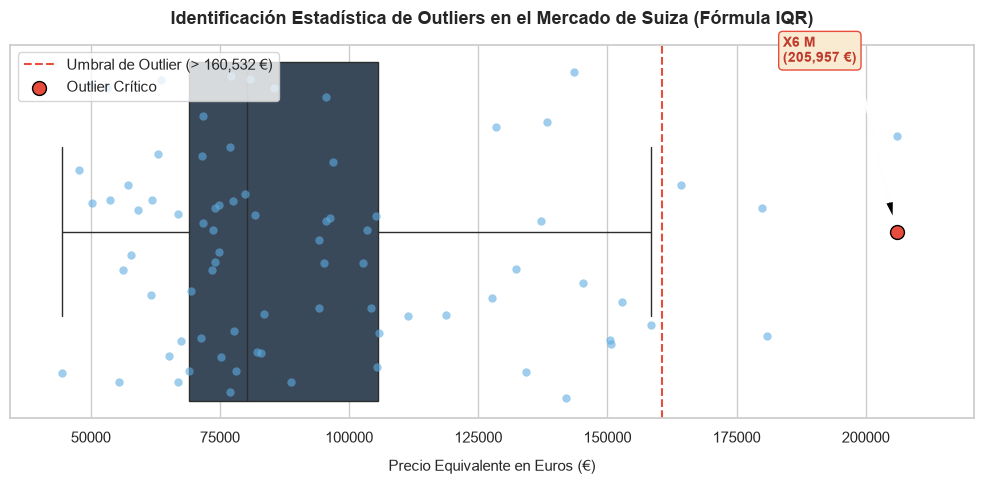

In [58]:
#Representación gráfica del outlier en Suiza: Modelo X6 M 
#Valor convertido a €: 205957
#Diagrama de caja o boxplot 

import matplotlib.pyplot as plt
import seaborn as sns 

#Filtrar datos limpios de Suiza 
col_suiza = 'Suiza_Euro'
df_grafico = df[(df[col_suiza].notna()) & (df[col_suiza] > 0)].copy()

#Tamaño y estilo del gráfico
plt.figure(figsize=(10,5))
sns.set_theme(style="whitegrid")

#Dibujar caja 
sns.boxplot(
    data=df_grafico,
    x=col_suiza,
    color='#34495e',  # Gris oscuro elegante para la caja principal
    width=0.3,
    fliersize=0       # Ocultamos los puntos de outliers nativos para pintarlos personalizados
)

#Mostrar densidad real de los modelos 
sns.stripplot(
    data=df_grafico,
    x=col_suiza,
    color='#5dade2',  # Azul claro para los puntos normales del catálogo
    size=6,
    alpha=0.6,
    jitter=0.15
)

#Línea de IQR (DISCONTINUA)
Q1 = df_grafico[col_suiza].quantile(0.25)
Q3 = df_grafico[col_suiza].quantile(0.75)
IQR = Q3 - Q1
umbral_superior = Q3 + 1.5 * IQR
plt.axvline(x=umbral_superior, color='#e74c3c', linestyle='--', linewidth=1.5, label=f'Umbral de Outlier (> {int(umbral_superior):,} €)')

#Identificación del outlier BMW X6 M en el gráfico 

x6m_data = df_grafico[df_grafico['Modelo'].str.contains('X6 M', case=False, na=False)]

if not x6m_data.empty:
    precio_x6m = int(x6m_data[col_suiza].values[0])
    nombre_x6m = x6m_data['Modelo'].values[0]
    
    # Destacar el punto del X6 M con un color rojo de alerta
    plt.scatter(precio_x6m, 0, color='#e74c3c', s=100, zorder=5, edgecolor='black', label='Outlier Crítico')
    
    # Etiqueta de texto flotante con una flecha apuntando al punto
    plt.annotate(
        f"{nombre_x6m}\n({precio_x6m:,} €)",
        xy=(precio_x6m, 0),
        xytext=(precio_x6m - 22000, -0.15),
        arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6),
        fontsize=10,
        fontweight='bold',
        color='#c0392b',
        bbox=dict(boxstyle="round,pad=0.3", fc="#f9ebd2", ec="#e74c3c", lw=1)
    )

#Formatear
plt.title('Identificación Estadística de Outliers en el Mercado de Suiza (Fórmula IQR)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Precio Equivalente en Euros (€)', fontsize=11, labelpad=10)
plt.gca().set_yticks([]) # Ocultamos el eje Y ya que es una sola dimensión de precios
plt.xlim(df_grafico[col_suiza].min() - 10000, df_grafico[col_suiza].max() + 15000)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()



En Suiza, observamos que el X6 M es el outlier más elevado. Aquí se dan varios factores para que esto suceda: 
- A pesar de que su tipo impositivo es menor que el del entorno de la Unión Europea (8.1% frente, por ejemplo, al 23% de Portugal o el 19% de Alemania), aplica una normativa rigurosa que hace que este modelo se vea penalizado. 
- Sanciones por emisiones de CO2: Suiza no es parte de la Unión Europea, pero sigue muy de cerca sus objetivos climáticos. Este modelo, debido a sus características técnicas, sufre una penalización directa en su coste final a la hora de la importacio y posterior homologación, dando lugar a un precio final inflado, hasta los 205.957€. 
- También se suma a este precio un 4% sobre el valor de importación de cualquier vehículo, abriendo aún más la brecha entre coches de base con precio muy elevado, como es este caso. 

<span style="font-size: 15pt; font-weight: bold; color: #009dcd;">**25. CONCLUSIONES FINALES**</span>

**1. Fragmentación y asimetría del mercado europeo** 

El catálogo de bmw para el 2026 muestra que no existe un mercado único en lo que a estrategia de precios se refiere. Esto se debe a varios motivos, entre ellos las cargas impositivas y las regulaciones locales de cada país en materia de emisiones de C02, provocando una falta de homogeneidad.

Modelos de volumen masivo como el ix1 eDrive 20, o el X1 xdrive 25e muestran unas enormes brechas de arbitraje (255,5% y 193,23% en cada caso), donde el precio de Suiza llega incluso a triplicar el precio minimo de Italia. La marca, por tanto, altera los precios netos en cada país para poder absorber las penalizaciones por emisiones o adaptarse a las ayudas de movilidad eléctrica promovidas por cada gobierno. 

**2. Portugal y Suiza: polos de alta dispersión financiera**

Al analizar el Coeficiente de variación (cv) y las rutras de arbitraje, Portugal y Suiza se muestran como los mercados más singulares y caros. 

- Portugal muestra un CV de 47.78%, siendo éste el país con mayor dispersión de precios, debida a su impuesto de matriculación, que penaliza a motores con gran cilindrada. Un ejemplo es el X5 M, con un precio máximo de 232.050€, duplicando el precio de Suiza (111.489€). 
- Suiza presenta un cv DE 38.30%. Tiene una moneda fuerte (CHF- Franco Suizo) y un poder adquisitivo muy alto. Aquí los precios suelo o de entrada son mucho más elevados. Un Serie 1 básico o el X1 pueden arrancar en precios notablemente superiores al del resto del continente, y esto confirma la estrategia que permite exprimir el margen de ganancias en regiones con gran disposición a pagar (willingness to pay). 

**3. "Prima de estatus" SUV frente a la racionalidad Touring** 

Al analizar la segmentación por tipo de carrocería en el mercado de Suiza (tomado como neutral), observamos que: 

- Los modelos tipo SUV parten de un precio medio de 113.273, frente a 91.259€ de berlinas y familiares. Esto demuestra la presencia de la prima de estatus en la gama X/iX, elevando los precios de entrada por la tendencia del mercado y la percepción de estatus por parte del comprador. 
- El Touring se muestra como alternativa. Son un 20% más asequibles que la gama suv. Se considera que la carrocería familiar es una alternativa financiera óptima, para familias que buscan espacio y habitabilidad sin pagar el sobreprecio de un SUV.

**4. Efecto frontera: ventajas de arbitraje para el consumidor**

Para modelos de alto rendimiento bajo el emblema M, y los descapotables (como el Serie 4 cabrio), la diferencia de precios supone una oportunidad de compra entre fronteras. Un comprador de Francoa o Portugal (donde hay mayor penalización por CO2 o impuesto por cilindrada) ve un mayor incentivo financiero real al adquirir determinados modelos en Italia o Alemania (que registran los precios mínimos de la muestra), asumiendo el coste del viaje y de importación a cambio de un ahorro que en el caso del X5 M puede superar los 40.000€. 

El catálogo de BMW para el 2026 muestra una estrategia de pricing demográfico muy segmentada. La marca aprovecha la baja elasticidad del precio en mercados ricos como Suiza, y se aprecia especialmente en segmentos de lujo (SUV, gama M), permitiendo así maximizar su rentabilidad. A la vez sacrifica márgenes o reestructura precios en países con una alta carga impositiva o fuertes ayudas a la compra (como Francia o portugal). Esto da lugar a grandes brechas de precios en modelos similares de hasta 3 dígitos, haciendo que el mercado europeo esté fragmentado y abriendo ventanas de arbitraje geográfico para el comprador más astuto. 